# Step 1 - Exploratory data analysis (Ilgaz)

**Task:** `prom_300_all` from the GUE benchmark (DNABERT-2). Each row is a 300-letter human DNA sequence; label 1 = promoter, 0 = not promoter.

**Plan (simple → hard):**

| # | Section | Question |
|---|---|---|
| 1 | Files on disk | What exactly did we download? |
| 2 | First look | Columns, types, `head()`, labels |
| 3 | Sanity checks | Missing values, lengths, alphabet, case, label values, the 6-mer JSON files |
| 4 | Duplicates and leakage | Same sequence twice, across splits, with both labels, or as reverse complement |
| 5 | Reading a few sequences | What does a promoter look like by eye? |
| 6 | Base composition | A/C/G/T shares, GC content, Chargaff's 2nd rule, skews |
| 6b | G vs C, A vs T: the extra letters | Strand asymmetry (skew), overall and by position |
| 7 | Dinucleotides and CpG | CpG observed/expected vs. what real human DNA should show |
| 8 | Complexity and repeats | Entropy, homopolymers, tandem repeats |
| 8b | Is entropy maximized? | Ceiling vs random-300 vs shuffled, per sequence / position / block |
| 9 | Position | Where along the 300 letters do the classes differ? (TSS at 250) |
| 10 | Core promoter motifs | TATA, Inr, CCAAT, GC box, DPE, BRE: how often and where |
| 11 | k-mers | Vocabulary coverage, Zipf, most enriched 6-mers |
| 12 | Split consistency | Are dev and test drawn like train? |
| 13 | Correlations | Handcrafted features vs. label and vs. each other |
| 14 | Low-dimensional view | PCA / t-SNE on 3-mer profiles |
| 15 | Simple-feature baselines | How far do handcrafted features get? |
| 16 | How were the negatives made? | Testing the "8 of 20 blocks kept" construction |
| 17 | Summary | What this means for the models |

Coordinates: positions are **1-based**. In GUE `prom_300` the window is −249…+50 around the transcription start site (TSS), so **the TSS is position 250**.

In [1]:
import hashlib, json, re, time
from collections import Counter, defaultdict
from itertools import product
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

DATA_DIR = Path("..") / "data" / "prom_300_all"   # Code/data/prom_300_all
RESULTS_DIR = Path("results"); RESULTS_DIR.mkdir(exist_ok=True)
PROM, NON, GREY = "#2a78d6", "#eb6834", "#8a8984"  # blue = promoter (1), orange = not promoter (0)
CLASSES = [(1, PROM, "Promoter"), (0, NON, "Not promoter")]
BASE_COLORS = {"A": "#3a9d5d", "C": "#2a78d6", "G": "#e8a33d", "T": "#d1495b"}
TSS = 250
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#ecebe8", "figure.dpi": 110, "axes.axisbelow": True})
pd.set_option("display.max_colwidth", 80)

def _readable(lg, markerscale):
    for h in lg.legend_handles:
        try: h.set_alpha(1)
        except Exception: pass
    return lg

def leg_right(ax, title=None, markerscale=1, **kw):
    """Legend outside the axes, on the right."""
    return _readable(ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False, fontsize=9,
                               title=title, markerscale=markerscale, **kw), markerscale)

def leg_top(fig, ax, where="center", title=None, markerscale=1, **kw):
    """One figure-level legend above all panels (handles taken from `ax`)."""
    h, l = ax.get_legend_handles_labels()
    if ax.get_legend(): ax.get_legend().remove()
    x = {"center": 0.5, "left": 0.02, "right": 0.98}[where]
    loc = {"center": "upper center", "left": "upper left", "right": "upper right"}[where]
    return _readable(fig.legend(h, l, loc=loc, bbox_to_anchor=(x, 1.0), ncol=len(l), frameon=False, fontsize=9,
                                title=title, markerscale=markerscale, **kw), markerscale)

def save(fig, name, note=None):
    """Save a figure; `note` is a one-line takeaway printed under the plot. Legends outside are kept."""
    top = 0.9 if fig.legends else 1
    bottom = 0.07 if note else 0
    fig.tight_layout(rect=(0, bottom, 1, top))
    if note:
        fig.text(0.5, 0.012, note, ha="center", va="bottom", fontsize=9, style="italic", color="#3d3c39", wrap=True)
    fig.savefig(RESULTS_DIR / name, dpi=150, bbox_inches="tight")

def tss_line(ax):
    ax.axvline(TSS, color=GREY, ls="--", lw=1)

## 1. Files on disk
Before loading anything: which files are there, how big, and what do the first raw lines look like?

In [2]:
for f in sorted(DATA_DIR.iterdir()):
    md5 = hashlib.md5(f.read_bytes()).hexdigest()[:10]
    print(f"{f.name:<16} {f.stat().st_size/1e6:8.2f} MB   md5 {md5}")

dev.csv              1.79 MB   md5 b64697c626
dev_6mer.json       12.24 MB   md5 c84472a67d
test.csv             1.79 MB   md5 406050f93a
test_6mer.json      12.24 MB   md5 f8668fa691
train.csv           14.35 MB   md5 40eed3504c


train_6mer.json     97.93 MB   md5 7f32ab29a4


In [3]:
for name in ("train.csv", "dev.csv"):
    with open(DATA_DIR / name) as fh:
        print(f"--- {name}, first 3 raw lines (cut at 90 chars) ---")
        for _ in range(3): print(repr(fh.readline()[:90]))
with open(DATA_DIR / "dev_6mer.json") as fh:
    print("--- dev_6mer.json, first 150 chars ---\n", fh.read(150))

--- train.csv, first 3 raw lines (cut at 90 chars) ---
'sequence,label\n'
'TATAATAATAACGAAGATGAGACGACAGTCGACAAGAAAAGCACCAGCTGTCCCCGCCACATACAAGTATATGAGAAGGGGACGCGGGAG'
'AAAGCCCGAGCGGCGGCCACGCCTCGGTGGCGATTTTATTAGCGCTTGGTTGGGGTGGCCCGGCTGCCTGCGAGCGGGGTTTCCCCGCCC'
--- dev.csv, first 3 raw lines (cut at 90 chars) ---
'sequence,label\n'
'TAAATACGGAAGTTTATTACTTGAGGAATAGATGGAATCGTCGGGCGTGAGAGATCATAATCGGCTGCTTCTGGGAGCCGCACGTGGGAA'
'CGGGCCTGCCCCTCCGAGGCGCCGTAGCGCGGGAGGGAGGCGGCGGCGCTGTGGTCCGTGGGTCCGCCGGTCCGTGGGTCTGCCCGGCCG'
--- dev_6mer.json, first 150 chars ---
 ["TAAATA AAATAC AATACG ATACGG TACGGA ACGGAA CGGAAG GGAAGT GAAGTT AAGTTT AGTTTA GTTTAT TTTATT TTATTA TATTAC ATTACT TTACTT TACTTG ACTTGA CTTGAG TTGAGG T


`dev.csv` and `test.csv` have exactly the same size but different MD5 hashes: every row has a fixed width (300 letters + comma + label), so the same number of rows gives the same size. The `_6mer.json` files are lists of strings of space-separated overlapping 6-mers (the DNABERT-1 input format). Section 3 checks that they match the CSVs.

## 2. First look

In [4]:
train, dev, test = [pd.read_csv(DATA_DIR / f"{s}.csv") for s in ("train", "dev", "test")]
splits = {"train": train, "dev": dev, "test": test}
for n, d in splits.items(): print(f"{n:<5} shape={d.shape}  columns={list(d.columns)}  dtypes={d.dtypes.to_dict()}")
train.head()

train shape=(47356, 2)  columns=['sequence', 'label']  dtypes={'sequence': <StringDtype(na_value=nan)>, 'label': dtype('int64')}
dev   shape=(5920, 2)  columns=['sequence', 'label']  dtypes={'sequence': <StringDtype(na_value=nan)>, 'label': dtype('int64')}
test  shape=(5920, 2)  columns=['sequence', 'label']  dtypes={'sequence': <StringDtype(na_value=nan)>, 'label': dtype('int64')}


,sequence,label
0,TATAATAATAACGAAGATGAGACGACAGTCGACAAGAAAAGCACCAGCTGTCCCCGCCACATACAAGTATATGAGA...,0
1,AAAGCCCGAGCGGCGGCCACGCCTCGGTGGCGATTTTATTAGCGCTTGGTTGGGGTGGCCCGGCTGCCTGCGAGCG...,1
2,AGTCCGCGATATTCTGAGGGGACTTTCGACACAAAAAAGTTGACACGGGTCGTTTGGGAATTCAGTCACCTTTTTC...,0
3,ACCCCCCGGCCCCGCCCCACAGACCCCTCCAGTGGTCCCCCGGCCACGCGGGCTCCGGGGGGGCGGGGCGGGGGCG...,1
4,AGGTCTTTGGTCCCCCAACCCTGTGCTCTTTCCACTTAAATCCCGATGGTTTCTTACAGAGTTCTAATAGTCTGAG...,1


In [5]:
train.info(memory_usage='deep')

<class 'pandas.DataFrame'>
RangeIndex: 47356 entries, 0 to 47355
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   sequence  47356 non-null  str  
 1   label     47356 non-null  int64
dtypes: int64(1), str(1)
memory usage: 14.3 MB


In [6]:
pd.concat({n: d.label.value_counts().sort_index() for n, d in splits.items()}, axis=1).assign(
    total=lambda t: t.sum(axis=1)).T.assign(promoter_share=lambda t: (t[1] / (t[0] + t[1])).round(3))

label,0,1,promoter_share
train,23684,23672,0.500
dev,2974,2946,0.498
test,2940,2980,0.503
total,29598,29598,0.500


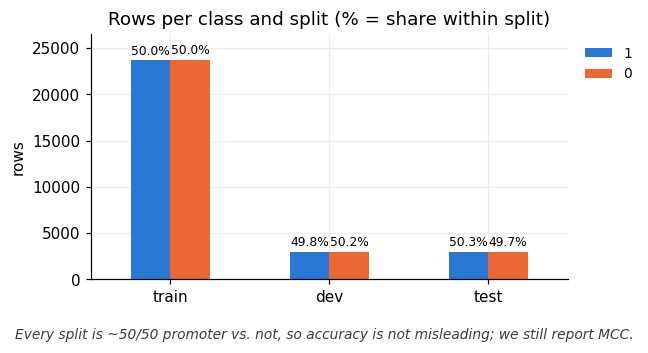

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.2))
vc = pd.concat({n: d.label.value_counts().sort_index() for n, d in splits.items()}, axis=1).T
vc[[1, 0]].plot.bar(ax=ax, rot=0, color=[PROM, NON]); ax.legend(["Promoter", "Not promoter"]); leg_right(ax)
share = vc[[1, 0]].div(vc.sum(axis=1), axis=0)
for cont, col in zip(ax.containers, [1, 0]):
    ax.bar_label(cont, labels=[f"{v:.1%}" for v in share[col]], fontsize=8, padding=2)
ax.margins(y=0.12)
ax.set(title="Rows per class and split (% = share within split)", ylabel="rows"); save(fig, "eda_01_class_balance.png",
     "Every split is ~50/50 promoter vs. not, so accuracy is not misleading; we still report MCC.")

Two columns: `sequence` (string) and `label` (int). Each split is almost exactly 50/50, so accuracy isn't misleading, but we still report MCC to match the DNABERT-2 paper.

## 3. Sanity checks
Checks that make sense for DNA sequence data:
- no missing values, `label` only 0/1
- every sequence has exactly 300 letters
- **alphabet:** A/C/G/T only. IUPAC ambiguity codes (N, R, Y, ...) mean unknown bases.
- **case:** lowercase in genome FASTA usually means *soft-masked repeats*, so mixed case would carry hidden information
- no spaces or line breaks inside sequences
- the `_6mer.json` files are exactly the overlapping 6-mers of the CSV rows, in the same order

In [8]:
IUPAC = set("ACGTRYSWKMBDHVN")
checks = []
for n, d in splits.items():
    s = d.sequence
    letters = Counter("".join(s))
    checks += [
        (n, "no missing values", d.isna().sum().sum() == 0, int(d.isna().sum().sum())),
        (n, "label in {0,1}", set(d.label.unique()) <= {0, 1}, sorted(d.label.unique().tolist())),
        (n, "all length 300", (s.str.len() == 300).all(), sorted(s.str.len().unique().tolist())),
        (n, "uppercase only (no soft-masking)", not s.str.contains("[a-z]").any(), int(s.str.contains("[a-z]").sum())),
        (n, "no whitespace", not s.str.contains(r"\s").any(), int(s.str.contains(r"\s").sum())),
        (n, "only valid IUPAC letters", set(letters) <= IUPAC, "".join(sorted(letters))),
        (n, "only A/C/G/T", set(letters) <= set("ACGT"), {k: v for k, v in letters.items() if k not in "ACGT"}),
    ]
pd.DataFrame(checks, columns=["split", "check", "passed", "detail"])

,split,check,passed,detail
0,train,no missing values,True,0
1,train,"label in {0,1}",True,"[0, 1]"
2,train,all length 300,True,[300]
3,train,uppercase only (no soft-masking),True,0
4,train,no whitespace,True,0
5,train,only valid IUPAC letters,True,ACGT
6,train,only A/C/G/T,True,{}
7,dev,no missing values,True,0
8,dev,"label in {0,1}",True,"[0, 1]"
9,dev,all length 300,True,[300]


In [9]:
# Letter counts and % per split, including N (unknown base)
lc = {}
for n, d in splits.items():
    c = Counter("".join(d.sequence)); lc[n] = {b: c[b] for b in "ACGTN"}
lc = pd.DataFrame(lc).T; lc.loc["all"] = lc.sum()
lc["total"] = lc.sum(axis=1)
pct = lc[list("ACGTN")].div(lc.total, axis=0) * 100
pd.concat({"count": lc, "%": pct.round(6)}, axis=1)

count                                                  %             \
             A        C        G        T  N     total          A          C   
train  2967713  4047835  4167321  3023931  0  14206800  20.889384  28.492236   
dev     372352   504846   520042   378759  1   1776000  20.965766  28.426014   
test    370131   507053   519822   378994  0   1776000  20.840709  28.550282   
all    3710196  5059734  5207185  3781684  1  17758800  20.892155  28.491418   

                                       
               G          T         N  
train  29.333284  21.285096  0.000000  
dev    29.281644  21.326520  0.000056  
test   29.269257  21.339752  0.000000  
all    29.321717  21.294705  0.000006

In [10]:
# The one non-ACGT row: where is the N?
bad = dev[dev.sequence.str.contains("[^ACGT]")]
for i, r in bad.iterrows():
    p = [m.start() + 1 for m in re.finditer("[^ACGT]", r.sequence)]
    print(f"dev row {i}, label {r.label}, non-ACGT at position(s) {p}: ...{r.sequence[p[0]-11:p[0]+10]}...")
    q = p[0] - 1; blk = q // 15
    print(f"  block {blk+1} (positions {blk*15+1}-{blk*15+15}), {p[0]-TSS} relative to the TSS; context ±20: {r.sequence[q-20:q]} [N] {r.sequence[q+1:q+21]}")
    # Is this promoter the parent of a hybrid negative? If so, does the negative reveal the real letter?
    for n, d in splits.items():
        for j, x in d[d.label == 0].sequence.items():
            shared = sum(x[b*15:(b+1)*15] == r.sequence[b*15:(b+1)*15] for b in range(20))
            if shared >= 3:
                print(f"  parent of {n} negative row {j}: shares {shared}/20 blocks; block {blk+1} kept: "
                      f"{x[blk*15:(blk+1)*15] == r.sequence[blk*15:(blk+1)*15]} (letter there: {x[q]}, random filler)")

dev row 4842, label 1, non-ACGT at position(s) [201]: ...AGGAGGTGGGNCCGCCGTCGC...
  block 14 (positions 196-210), -49 relative to the TSS; context ±20: GCGGGGGCGCAGGAGGTGGG [N] CCGCCGTCGCCGTCAGGGCC


  parent of train negative row 22286: shares 8/20 blocks; block 14 kept: False (letter there: T, random filler)


In [11]:
# 6-mer JSON files: same rows, same order, exactly the overlapping 6-mers (stride 1 -> 295 per row)?
def kmers(s, k=6): return " ".join(s[i:i+k] for i in range(len(s) - k + 1))
for n, d in splits.items():
    js = json.load(open(DATA_DIR / f"{n}_6mer.json"))
    same = sum(a == kmers(b) for a, b in zip(js, d.sequence))
    print(f"{n}: json rows={len(js)}, csv rows={len(d)}, rows that match exactly={same} ({same/len(d):.2%}), tokens/row={len(js[0].split())}")

train: json rows=47356, csv rows=47356, rows that match exactly=47356 (100.00%), tokens/row=295
dev: json rows=5920, csv rows=5920, rows that match exactly=5920 (100.00%), tokens/row=295


test: json rows=5920, csv rows=5920, rows that match exactly=5920 (100.00%), tokens/row=295


Everything passes except one `N` in one dev row (a single unknown base, harmless). The JSON files add no information; they are the same data, pre-tokenized for DNABERT-1. **From here on we only use the CSVs.**

## 4. Duplicates and leakage
- exact duplicates inside a split
- the same sequence in two splits (train → test leakage)
- the same sequence with **both labels** (label noise)
- **reverse complements:** DNA is double-stranded, so `ACGGT` and its reverse complement `ACCGT` are the same stretch of genome read from the other strand

In [12]:
COMP = str.maketrans("ACGTN", "TGCAN")
def rc(s): return s.translate(COMP)[::-1]

rows = []
for n, d in splits.items():
    g = d.groupby("sequence").label.agg(["size", "nunique"])
    rows.append({"split": n, "rows": len(d), "unique sequences": len(g),
                 "duplicate rows": int(len(d) - len(g)),
                 "sequences with both labels": int((g["nunique"] > 1).sum())})
pd.DataFrame(rows)

,split,rows,unique sequences,duplicate rows,sequences with both labels
0,train,47356,47242,114,11
1,dev,5920,5919,1,0
2,test,5920,5917,3,0


In [13]:
sets = {n: set(d.sequence) for n, d in splits.items()}
rcsets = {n: {rc(s) for s in v} for n, v in sets.items()}
rows = []
for a, b in [("train", "dev"), ("train", "test"), ("dev", "test")]:
    rows.append({"pair": f"{a} & {b}", "identical sequences": len(sets[a] & sets[b]),
                 "reverse-complement matches": len(sets[a] & rcsets[b])})
for n in splits:
    rows.append({"pair": f"{n} & itself", "identical sequences": None,
                 "reverse-complement matches": sum(1 for s in sets[n] if rc(s) in sets[n] and rc(s) != s)})
pd.DataFrame(rows)

,pair,identical sequences,reverse-complement matches
0,train & dev,39.0,0
1,train & test,19.0,0
2,dev & test,1.0,0
3,train & itself,NaN,6
4,dev & itself,NaN,0
5,test & itself,NaN,0


In [14]:
# Of the train/test overlaps, do labels agree?
m = train.merge(test, on="sequence", suffixes=("_train", "_test"))
print(f"{len(m)} rows: label agreement = {(m.label_train == m.label_test).mean():.0%}")
print(m.groupby(["label_train", "label_test"]).size())

21 rows: label agreement = 100%
label_train  label_test
0            0              4
1            1             17
dtype: int64


Duplicates and cross-split overlap are small (<0.5% of any split). They're worth one sentence in the report, but they won't change any model ranking. Reverse-complement copies are essentially absent: each sequence appears on one strand only.

## 5. Reading a few sequences
Positions 241–259 (around the TSS at 250) are printed in lowercase to make them easy to find.

In [15]:
def show(s, width=100):
    s = s[:240] + s[240:259].lower() + s[259:]
    for i in range(0, 300, width): print(f"{i+1:>4} {s[i:i+width]}")
for lab, _, name in CLASSES:
    for i, s in enumerate(train.sequence[train.label == lab].sample(2, random_state=1)):
        print(f"\n== {name} example {i+1} ==  GC={(s.count('G')+s.count('C'))/3:.0f}%"); show(s)


== Promoter example 1 ==  GC=53%
   1 TTGAACCTTCTGTATGCCCGTTGGGCCCCCGGCTTGCCCTTCTTGCTCAGATCAAGAATCCCCTTCCATGTCTTTCTCCCAGATTTACGTCCCCATCCTT
 101 GAAGGCCAAGCGTTATGTCACTTTGTCAAAGCTTCCCTGGATTCTCCCATCAGACTTCAGCAGGGAAAGAGGAAGGCTGAGCTCATCTCTTTCCTCTGAG
 201 CATCTTGGGCTCCCTGCCTATGACGCTGGCTGCCCTTCTCcttggaccaagccttctgcTAGACTCTCAGCTCTCAGAGAGCAGAGACCAGTCTACCTCA

== Promoter example 2 ==  GC=60%
   1 AAAGGCGCACTGTGAACTGGCTCTTTCTTTCCGCCAATCATTTCCGCCAGCCATTCATCACCGATTTTCTTCATCTTCCCCTCCCTCTTCCGTCCCGCAG
 101 TCCCCGACCTGTTAGCTCTCGGTTAGTTAAGGGACTCGGGTCCTTCCGAACTGCGCATGCGCCACCGCGTCTGCAGGGGGAGAAGCGGGCAGGGGCGCAG
 201 GCGCAGTAGTGTGATCCCCTGGCCAGTCCCTAAGCACGTGggttgggttgtcctgcttgGCTGCGGAGGGAGTGGAACCTCGATATTGGTGGTGTCCATC

== Not promoter example 1 ==  GC=53%
   1 CCAGAGGTCTAATGCGAGACGTATTTAGCAGGAGCTTAAGAAACACTACACGGCTGCGGTGTTGAGTCTGACCCTTAGTAGTGCCTTGCGGGCTGGGGAC
 101 CGGCACGGTGGCTGCGCGTTGTCAGTCAGCCAGTAATCGCTGACAGTCTCGGGATAGAGCGTGCAGAGTTGCTGCAGCTCGTAGACACTAACCCTTCGCG
 201 TGCTACAAATGAGGTAAAGTTACGTGAAACTCTGTAATTTc

By eye: promoters often show GC-rich runs (`GGGCGG`, `CCGCCC`) near the TSS. Non-promoters look like an even mix of all four letters. Section 16 explains why.

## 6. Base composition
- **GC content:** promoters, especially human CpG-island promoters, are GC-rich. The human genome average is about 41% GC.
- **Chargaff's 2nd parity rule:** in long stretches of a *single* strand, %A ≈ %T and %C ≈ %G. Real genomic DNA follows it closely, while random or edited sequences may not.
- **Skews:** GC skew = (G−C)/(G+C) and AT skew = (A−T)/(A+T). Real promoters are known to have a positive GC skew downstream of the TSS.

In [16]:
def comp_table(df):
    tot = {lab: Counter("".join(df.sequence[df.label == lab])) for lab in (0, 1)}
    t = pd.DataFrame({name: {b: tot[lab][b] / sum(tot[lab][x] for x in "ACGT") for b in "ACGT"} for lab, _, name in CLASSES})
    return t
comp = comp_table(train); print((comp * 100).round(2))

for d in splits.values():
    d["gc"] = (d.sequence.str.count("G") + d.sequence.str.count("C")) / 300
    d["gc_skew"] = (d.sequence.str.count("G") - d.sequence.str.count("C")) / (d.sequence.str.count("G") + d.sequence.str.count("C"))
    d["at_skew"] = (d.sequence.str.count("A") - d.sequence.str.count("T")) / (d.sequence.str.count("A") + d.sequence.str.count("T"))
print("\nGC content by class:"); print(train.groupby("label").gc.describe().round(3))

   Promoter  Not promoter
A     19.18         22.60
C     30.17         26.82
G     31.08         27.59
T     19.57         23.00



GC content by class:
         count   mean    std    min    25%    50%    75%    max
label                                                          
0      23684.0  0.544  0.064  0.217  0.507  0.550  0.587  0.827
1      23672.0  0.612  0.121  0.227  0.530  0.623  0.703  0.940


In [17]:
# Chargaff's 2nd rule per sequence: |A-T|/(A+T) and |C-G|/(C+G), compared with a shuffled control
rng = np.random.default_rng(0)
def chargaff(s):
    a, c, g, t = (s.count(x) for x in "ACGT")
    return abs(a - t) / max(a + t, 1), abs(c - g) / max(c + g, 1)
ch = pd.DataFrame(train.sequence.map(chargaff).tolist(), columns=["AT_imbalance", "CG_imbalance"]); ch["label"] = train.label
print(ch.groupby("label").mean().round(3))
rand = ["".join(rng.choice(list("ACGT"), 300)) for _ in range(5000)]
print("uniform random 300-mers:", np.round(np.mean([chargaff(s) for s in rand], axis=0), 3))

       AT_imbalance  CG_imbalance
label                            
0             0.084         0.089
1             0.130         0.122


uniform random 300-mers: [0.066 0.065]


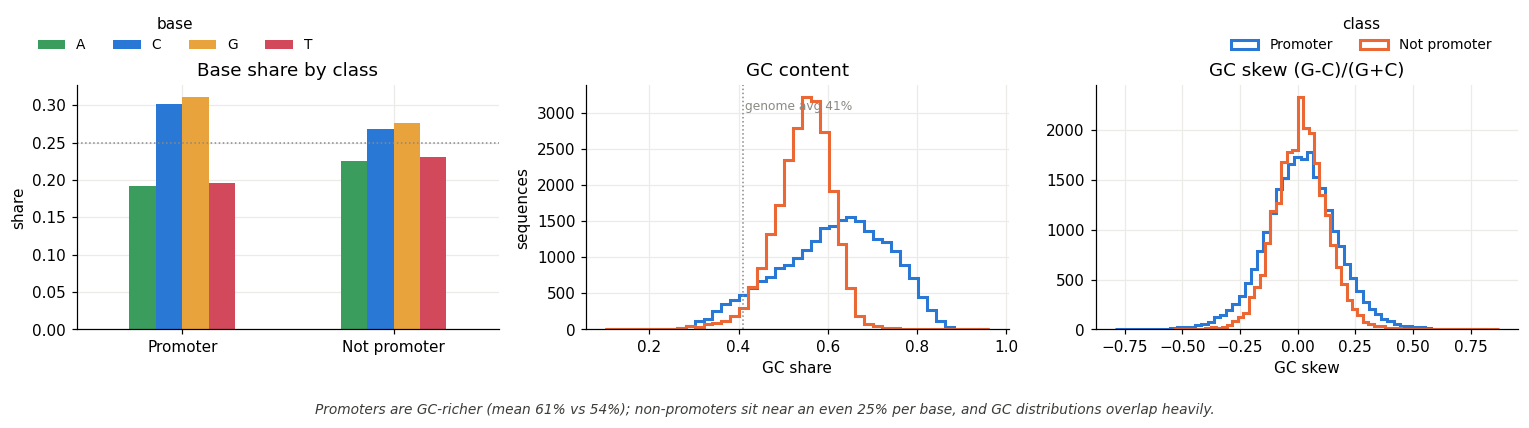

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
comp.T.plot.bar(ax=ax[0], rot=0, color=[BASE_COLORS[b] for b in "ACGT"]); ax[0].set(title="Base share by class", ylabel="share"); leg_top(fig, ax[0], "left", title="base")
ax[0].axhline(0.25, color=GREY, ls=":", lw=1)
bins = (np.arange(30, 290, 6) + 0.5) / 300
for lab, c, n in CLASSES:
    ax[1].hist(train.gc[train.label == lab], bins=bins, histtype="step", lw=2, color=c, label=n)
    ax[2].hist(train.gc_skew[train.label == lab], bins=60, histtype="step", lw=2, color=c, label=n)
ax[1].axvline(0.41, color=GREY, ls=":", lw=1); ax[1].text(0.415, ax[1].get_ylim()[1]*0.9, "genome avg 41%", fontsize=8, color=GREY)
ax[1].set(title="GC content", xlabel="GC share", ylabel="sequences")
ax[2].set(title="GC skew (G-C)/(G+C)", xlabel="GC skew"); leg_top(fig, ax[2], "right", title="class")
save(fig, "eda_02_composition.png",
     f"Promoters are GC-richer (mean {train.gc[train.label==1].mean():.0%} vs {train.gc[train.label==0].mean():.0%}); non-promoters sit near an even 25% per base, and GC distributions overlap heavily.")

Promoters are GC-rich (mean ~61% vs. ~54%), and both classes are well above the 41% genome average. Non-promoters are much closer to an even 25% per base, and their GC distribution is narrow. Both classes break Chargaff's 2nd rule more than random DNA does, promoters most of all (|A−T|/(A+T) 0.13 vs. 0.08 vs. 0.07 for random).

## 6b. G vs C and A vs T: the "extra" letters
G always pairs with C and A with T, so across **both** strands #G = #C and #A = #T. On the **one strand** we're given, they don't have to match. The surplus (G − C, A − T) is a strand asymmetry, usually normalized as a **skew**:

GC skew = (G − C) / (G + C)  AT skew = (A − T) / (A + T)

**Why it should matter for promoters:** transcription runs in one direction from the TSS. Human promoters are known to have a **G surplus (positive GC skew) just downstream of the TSS**, on the transcribed strand. This is linked to R-loops and transcription-coupled mutation, and it's strongest in CpG-island promoters. Random filler has no direction, so its skew should be ~0.

Questions:
1. Is the class difference in GC driven by G, by C, or both equally?
2. Do the overall per-sequence surpluses differ by class?
3. Does the surplus depend on **position**, i.e. does it flip at the TSS?
4. Does the up/downstream skew add information that total GC doesn't?

In [19]:
# 1+2. Overall surplus per sequence
for d in splits.values():
    d["g_minus_c"] = d.sequence.str.count("G") - d.sequence.str.count("C")
    d["a_minus_t"] = d.sequence.str.count("A") - d.sequence.str.count("T")
print("Class difference (promoter - non) in mean share: G %+.2f pp, C %+.2f pp, A %+.2f pp, T %+.2f pp" %
      tuple(100 * (comp.loc[b, "Promoter"] - comp.loc[b, "Not promoter"]) for b in "GCAT"))
print(train.groupby("label")[["g_minus_c", "a_minus_t", "gc_skew", "at_skew"]].agg(["mean", "std"]).round(3))
print("\nrandom 300-mers: std of G-C =", np.std([s.count("G") - s.count("C") for s in rand]).round(2))

Class difference (promoter - non) in mean share: G +3.48 pp, C +3.35 pp, A -3.41 pp, T -3.43 pp
      g_minus_c         a_minus_t         gc_skew        at_skew       
           mean     std      mean     std    mean    std    mean    std
label                                                                  
0         2.329  18.614    -1.207  14.728   0.015  0.114  -0.008  0.106
1         2.717  29.777    -1.168  19.131   0.015  0.157  -0.009  0.167

random 300-mers: std of G-C = 12.22


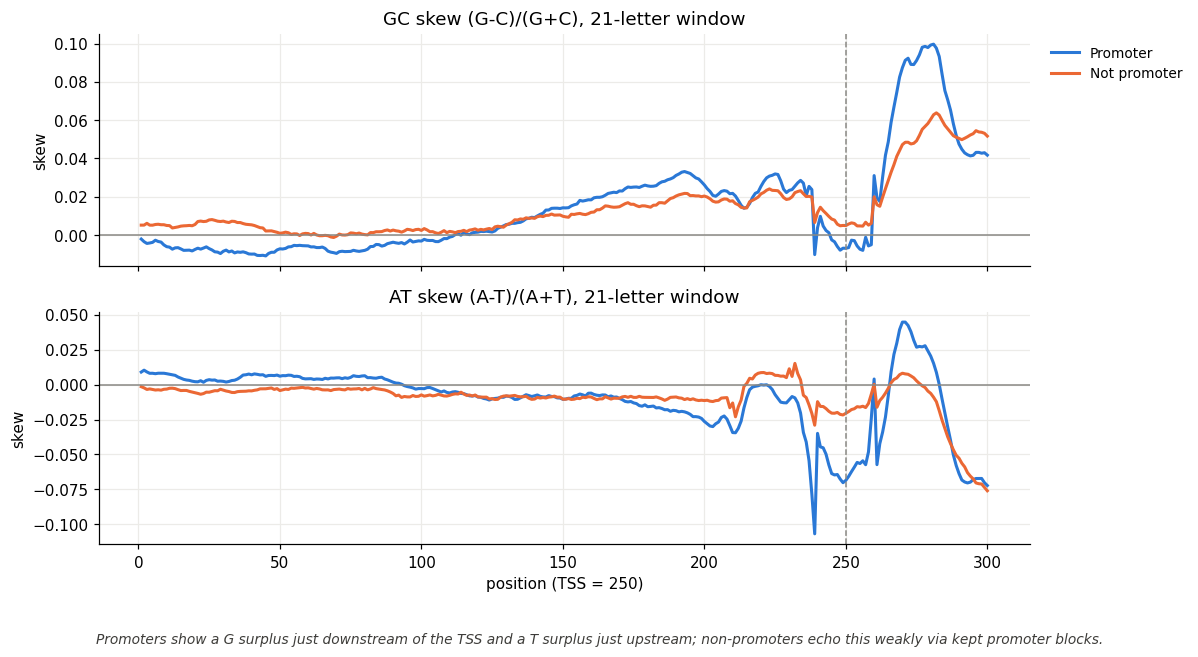

In [20]:
# 3. Skew by position: sliding window of 21 letters, per class (pooled counts)
def pos_skew(Lm, a, b, w=21):
    na, nb = (Lm == a).sum(0).astype(float), (Lm == b).sum(0).astype(float)
    k = np.ones(w)
    na, nb = np.convolve(na, k, "same"), np.convolve(nb, k, "same")
    return (na - nb) / (na + nb)
Lall = np.array([list(s) for s in train.sequence]); yall = train.label.values
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for lab, c, n in CLASSES:
    ax[0].plot(np.arange(1, 301), pos_skew(Lall[yall == lab], "G", "C"), color=c, lw=2, label=n)
    ax[1].plot(np.arange(1, 301), pos_skew(Lall[yall == lab], "A", "T"), color=c, lw=2, label=n)
for a, t in zip(ax, ["GC skew (G-C)/(G+C), 21-letter window", "AT skew (A-T)/(A+T), 21-letter window"]):
    a.axhline(0, color=GREY, lw=1); tss_line(a); a.set(title=t, ylabel="skew")
leg_right(ax[0])
ax[1].set_xlabel("position (TSS = 250)")
save(fig, "eda_02b_skew_by_position.png",
     "Promoters show a G surplus just downstream of the TSS and a T surplus just upstream; non-promoters echo this weakly via kept promoter blocks.")

In [21]:
# 4. Per-sequence skew upstream (1-240) vs downstream (256-300) of the TSS, and the switch between them
def skew(s, a, b):
    x, y_ = s.count(a), s.count(b); return (x - y_) / (x + y_) if x + y_ else 0.0
for d in splits.values():
    d["gc_skew_up"] = d.sequence.str[:240].map(lambda s: skew(s, "G", "C"))
    d["gc_skew_down"] = d.sequence.str[255:].map(lambda s: skew(s, "G", "C"))
    d["at_skew_up"] = d.sequence.str[:240].map(lambda s: skew(s, "A", "T"))
    d["at_skew_down"] = d.sequence.str[255:].map(lambda s: skew(s, "A", "T"))
    d["gc_skew_switch"] = d.gc_skew_down - d.gc_skew_up
cols = ["gc_skew_up", "gc_skew_down", "gc_skew_switch", "at_skew_up", "at_skew_down"]
for d in splits.values():
    d["abs_gc_skew"], d["abs_at_skew"] = d.gc_skew.abs(), d.at_skew.abs()
cols = cols + ["abs_gc_skew", "abs_at_skew"]
train.groupby("label")[cols].mean().round(3)

,gc_skew_up,gc_skew_down,gc_skew_switch,at_skew_up,at_skew_down,abs_gc_skew,abs_at_skew
label,,,,,,,
0,0.009,0.043,0.034,-0.005,-0.019,0.089,0.084
1,0.008,0.059,0.051,-0.005,-0.012,0.122,0.130


In [22]:
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
print("dev ROC-AUC of each skew feature alone:", {c: round(roc_auc_score(dev.label, dev[c]), 3) for c in cols})
# Does the skew add to GC? compare LogReg(gc) vs LogReg(gc + skews), fit on train, scored on dev
base = LogisticRegression().fit(train[["gc"]], train.label)
plus = LogisticRegression().fit(train[["gc"] + cols], train.label)
print("dev ROC-AUC  gc only: %.3f | gc + skews: %.3f" % (roc_auc_score(dev.label, base.predict_proba(dev[["gc"]])[:, 1]),
      roc_auc_score(dev.label, plus.predict_proba(dev[["gc"] + cols])[:, 1])))
# Within promoters: is the downstream G surplus stronger in GC-rich (CpG-island-like) promoters?
pr = train[train.label == 1]
print("\npromoters, mean downstream GC skew by GC tertile:"); print(pr.groupby(pd.qcut(pr.gc, 3, labels=["low GC", "mid GC", "high GC"]), observed=True).gc_skew_down.mean().round(3))

dev ROC-AUC of each skew feature alone: {'gc_skew_up': 0.502, 'gc_skew_down': 0.542, 'gc_skew_switch': 0.536, 'at_skew_up': 0.5, 'at_skew_down': 0.503, 'abs_gc_skew': 0.605, 'abs_at_skew': 0.63}
dev ROC-AUC  gc only: 0.697 | gc + skews: 0.738

promoters, mean downstream GC skew by GC tertile:
gc
low GC     0.036
mid GC     0.074
high GC    0.066
Name: gc_skew_down, dtype: float64


**Reading the "extra" letters:**
- **Which letters drive the GC difference?** G and C equally (+3.5 and +3.4 percentage points in promoters), and A and T drop equally (−3.4 each). The extra GC in promoters isn't one-sided.
- **Overall surplus:** the *average* G−C and A−T are the same in both classes (skew ≈ 0.015 and −0.01), so the signed skew has no power (dev ROC-AUC 0.50). But the *size* of the surplus differs: promoters have a much wider spread of G−C (std 29.8 letters vs. 18.6 for non-promoters and 12.2 for random DNA). |GC skew| and |AT skew| alone reach ROC-AUC 0.61–0.63, and adding the skews to GC raises its ROC-AUC from 0.70 to 0.74. In other words, promoters are lopsided one way or the other, while non-promoters are balanced like random DNA.
- **By position, the surplus has a clear shape in promoters:**
  - **G surplus downstream of the TSS** (GC skew up to +0.10 at ~270–285), the known transcription-direction signal. It's stronger in mid/high-GC promoters (0.07 vs. 0.04 in low-GC ones).
  - **T surplus (negative AT skew) just upstream of the TSS** (down to −0.10 at ~239, covering the TATA/−30 region), then an **A surplus at ~265–280**.
  - A slight C surplus in the first ~90 letters.
- **Non-promoters echo the same shape at about a third to two thirds of the strength.** That's what you'd expect if ~37% of each block is kept from a real promoter and the rest is random (Section 16). The last block is always kept, so at 290–300 the two curves meet.
- **For the models:** the information is in *where* the surplus is, not in its overall average. Bag-of-k-mers models can't see this position-specific signal; order-aware models (BiLSTM, DNABERT-2) can.

## 7. Dinucleotides and CpG
**Biology check:** across the human genome, the dinucleotide `CG` (CpG) is strongly *depleted*, because methylated C mutates to T. Its observed/expected ratio is about **0.2–0.25**. CpG islands, which often contain promoters, are the exception at ≥0.6.

observed/expected for XY = count(XY) × L / (count(X) × count(Y)). A value of 1 means "as often as chance".

CpG island rule (Gardiner-Garden & Frommer 1987): length ≥200, GC > 50%, CpG o/e > 0.6.

In [23]:
DIN = ["".join(p) for p in product("ACGT", repeat=2)]
def din_oe(seqs):
    big = "|".join(seqs)  # '|' stops dinucleotides crossing sequence boundaries
    mono = Counter(big); n = sum(mono[b] for b in "ACGT")
    di = Counter(big[i:i+2] for i in range(len(big) - 1))
    ndi = sum(di[x] for x in DIN)
    return pd.Series({x: (di[x] / ndi) / ((mono[x[0]] / n) * (mono[x[1]] / n)) for x in DIN})
oe = pd.DataFrame({name: din_oe(train.sequence[train.label == lab].tolist()) for lab, _, name in CLASSES})
oe["uniform random"] = din_oe(rand)
print(oe.round(2).T)

                  AA    AC    AG    AT    CA    CC    CG    CT    GA    GC  \
Promoter        1.29  0.72  1.21  0.82  1.02  1.14  0.73  1.19  1.00  1.04   
Not promoter    1.11  0.88  1.07  0.95  1.00  1.08  0.86  1.07  0.99  1.03   
uniform random  1.00  1.00  1.00  1.00  1.00  1.00  1.00  1.00  1.00  1.00   

                  GG    GT    TA    TC    TG    TT  
Promoter        1.12  0.74  0.68  0.99  1.02  1.29  
Not promoter    1.08  0.88  0.91  0.98  1.00  1.11  
uniform random  1.00  1.00  1.00  1.00  1.00  1.00  


        cpg_oe                                               
         count   mean    std  min    25%    50%    75%    max
label                                                        
0      23684.0  0.833  0.238  0.0  0.705  0.861  0.995  1.548
1      23672.0  0.640  0.319  0.0  0.345  0.724  0.898  1.644

Share meeting CpG-island criteria: {0: 0.702, 1: 0.584}


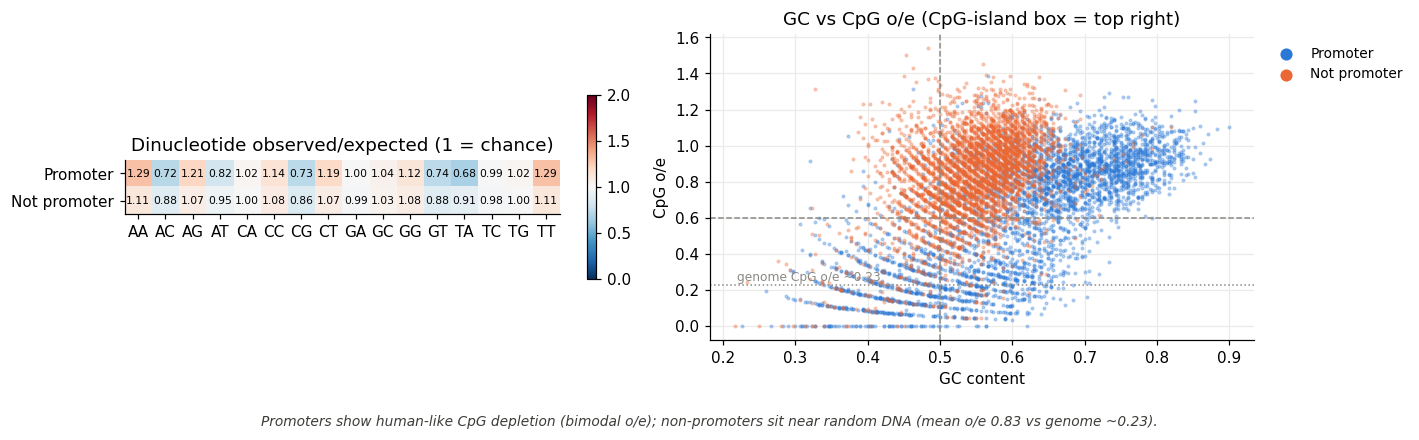

In [24]:
def cpg_oe(s):
    c, g = s.count("C"), s.count("G")
    return s.count("CG") * len(s) / (c * g) if c and g else 0.0
for d in splits.values():
    d["cpg_oe"] = d.sequence.map(cpg_oe)
    d["cpg_island"] = (d.gc > 0.5) & (d.cpg_oe > 0.6)
print(train.groupby("label")[["cpg_oe"]].describe().round(3))
print("\nShare meeting CpG-island criteria:", train.groupby("label").cpg_island.mean().round(3).to_dict())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
im = ax[0].imshow(oe[["Promoter", "Not promoter"]].T.values, cmap="RdBu_r", vmin=0, vmax=2)
ax[0].set_xticks(range(16)); ax[0].set_xticklabels(DIN); ax[0].set_yticks([0, 1]); ax[0].set_yticklabels(["Promoter", "Not promoter"]); ax[0].grid(False)
for j, x in enumerate(DIN):
    for i, cl in enumerate(["Promoter", "Not promoter"]): ax[0].text(j, i, f"{oe.loc[x, cl]:.2f}", ha="center", va="center", fontsize=7)
ax[0].set_title("Dinucleotide observed/expected (1 = chance)"); fig.colorbar(im, ax=ax[0], shrink=0.6)
for lab, c, n in CLASSES:
    ax[1].scatter(train.gc[train.label == lab][:4000], train.cpg_oe[train.label == lab][:4000], s=3, alpha=0.3, color=c, label=n)
ax[1].axhline(0.6, color=GREY, ls="--", lw=1); ax[1].axvline(0.5, color=GREY, ls="--", lw=1)
ax[1].axhline(0.23, color=GREY, ls=":", lw=1); ax[1].text(0.22, 0.25, "genome CpG o/e ~0.23", fontsize=8, color=GREY)
ax[1].set(xlabel="GC content", ylabel="CpG o/e", title="GC vs CpG o/e (CpG-island box = top right)"); leg_right(ax[1], markerscale=4)
save(fig, "eda_03_dinucleotides_cpg.png",
     f"Promoters show human-like CpG depletion (bimodal o/e); non-promoters sit near random DNA (mean o/e {train.cpg_oe[train.label==0].mean():.2f} vs genome ~0.23).")

**This is the most informative sanity check so far.**
- Promoters show the expected human pattern: CpG o/e is bimodal. Some sit low (~0.2–0.3, like ordinary genomic DNA: non-CpG-island promoters) and many are high (CpG-island promoters).
- Non-promoters have CpG o/e **around 0.8–0.9, close to random DNA (1.0)**. Real human non-promoter DNA would be strongly CpG-depleted (~0.2). In other words, **the negatives don't look like real human genomic DNA.** Section 16 tests why.
- So the classic CpG-island rule backfires here: *more* non-promoters (70%) than promoters (58%) pass it, because random DNA with GC > 50% passes it automatically.
- `TA` and `CG` are the most depleted dinucleotides in promoters (0.68, 0.73), as in real genomes. In non-promoters they're closer to 1.

## 8. Complexity and repeats
Low-complexity DNA (poly-A, `CACACA...` microsatellites) is common in real genomes. Random DNA has almost none.

In [25]:
def shannon(s, k):
    c = Counter(s[i:i+k] for i in range(len(s) - k + 1)); n = sum(c.values()); p = np.array(list(c.values())) / n
    return float(-(p * np.log2(p)).sum())
def longest_run(s): return max(len(m.group()) for m in re.finditer(r"(.)\1*", s))
STR = re.compile(r"((?:[ACGT]{1,3}?))\1{5,}")   # a 1-3 letter unit repeated >= 6 times
for d in splits.values():
    for k in (1, 2, 3): d[f"entropy_k{k}"] = d.sequence.map(lambda s: shannon(s, k))
    d["longest_homopolymer"] = d.sequence.map(longest_run)
    d["has_tandem_repeat"] = d.sequence.map(lambda q: bool(STR.search(q)))
cols = ["entropy_k1", "entropy_k2", "entropy_k3", "longest_homopolymer", "has_tandem_repeat"]
t = train.groupby("label")[cols].mean().round(3)
t.loc["uniform random"] = [np.mean([shannon(s, 1) for s in rand]), np.mean([shannon(s, 2) for s in rand]),
                           np.mean([shannon(s, 3) for s in rand]), np.mean([longest_run(s) for s in rand]),
                           np.mean([bool(STR.search(s)) for s in rand])]
t.round(3)

,entropy_k1,entropy_k2,entropy_k3,longest_homopolymer,has_tandem_repeat
label,,,,,
0,1.973,3.914,5.753,5.323,0.310
1,1.899,3.731,5.450,5.806,0.389
uniform random,1.993,3.963,5.839,4.815,0.188


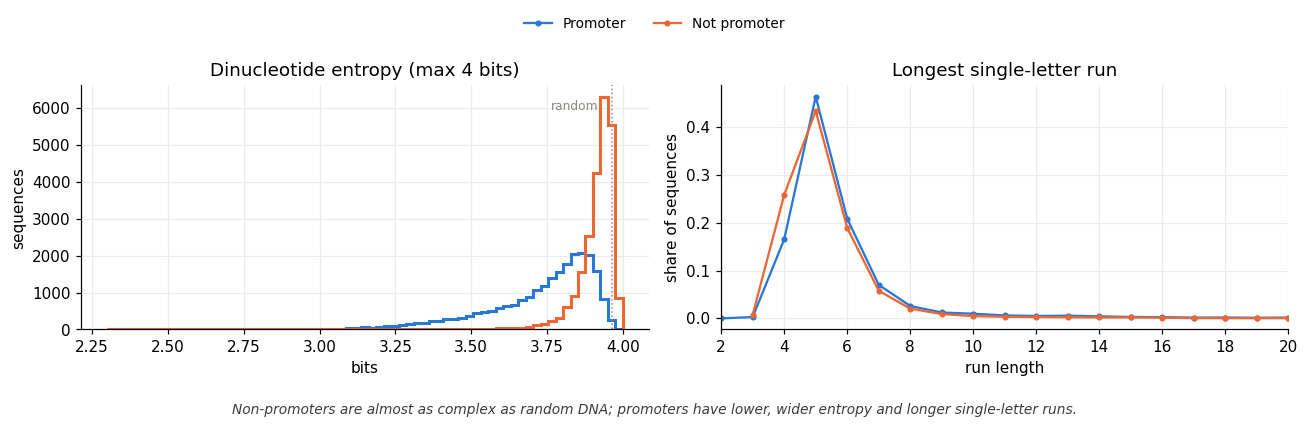

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for lab, c, n in CLASSES:
    ax[0].hist(train.entropy_k2[train.label == lab], bins=np.linspace(2.3, 4, 70), histtype="step", lw=2, color=c, label=n)
    v = train.longest_homopolymer[train.label == lab].value_counts(normalize=True).sort_index()
    ax[1].plot(v.index, v.values, marker="o", ms=3, color=c, label=n)
ax[0].axvline(np.mean([shannon(s, 2) for s in rand]), color=GREY, ls=":", lw=1); ax[0].text(3.92, ax[0].get_ylim()[1]*0.9, "random", fontsize=8, color=GREY, ha="right")
ax[0].set(title="Dinucleotide entropy (max 4 bits)", xlabel="bits", ylabel="sequences")
ax[1].set(title="Longest single-letter run", xlabel="run length", ylabel="share of sequences", xlim=(2, 20)); leg_top(fig, ax[1])
save(fig, "eda_04_complexity.png",
     "Non-promoters are almost as complex as random DNA; promoters have lower, wider entropy and longer single-letter runs.")

Non-promoters are close to the random reference on every complexity measure. Promoters have lower and more spread-out entropy, longer homopolymer runs and more tandem repeats, as real genomic DNA would.

## 8b. Is entropy maximized?
"Maximum entropy" = every letter (or letter pair) equally likely and independent: **2 bits per letter, 4 bits per dinucleotide.** Three references, from loose to strict:
1. **Theoretical ceiling** (2 / 4 bits). A 300-letter sequence can't reach it exactly: a finite sample always looks a little uneven.
2. **Random DNA of the same length:** the real achievable maximum, with a 95% range.
3. **The same sequence, letters shuffled:** the maximum *given its own letter counts*. If H(sequence) ≈ H(shuffled), the order carries no information (only the composition does). If it's lower, there is order structure (motifs, repeats).

We check it **per sequence**, **per position** (down the column of all sequences) and **per block** (kept vs. replaced blocks of the hybrid negatives).

In [27]:
rng = np.random.default_rng(3)
def shuffle(s): a = np.array(list(s)); rng.shuffle(a); return "".join(a)
rand_h2 = np.array([shannon("".join(rng.choice(list("ACGT"), 300)), 2) for _ in range(20000)])
lo, hi = np.percentile(rand_h2, [2.5, 97.5])
samp = pd.concat([train[train.label == lab].sample(4000, random_state=0) for lab in (0, 1)])
samp["h2_shuffled"] = samp.sequence.map(lambda s: np.mean([shannon(shuffle(s), 2) for _ in range(3)]))
samp["order_deficit"] = samp.h2_shuffled - samp.entropy_k2      # bits lost because of letter order
rows = []
for lab, _, n in CLASSES:
    g = samp[samp.label == lab]
    rows.append({"class": n, "H2 mean": g.entropy_k2.mean(), "gap to ceiling (4 bits)": 4 - g.entropy_k2.mean(),
                 "gap to random-300 mean": rand_h2.mean() - g.entropy_k2.mean(),
                 "share inside random 95% range": ((g.entropy_k2 >= lo) & (g.entropy_k2 <= hi)).mean(),
                 "H2 if shuffled": g.h2_shuffled.mean(), "order deficit (bits)": g.order_deficit.mean()})
rows.append({"class": "random 300-mers", "H2 mean": rand_h2.mean(), "gap to ceiling (4 bits)": 4 - rand_h2.mean(),
             "gap to random-300 mean": 0, "share inside random 95% range": 0.95, "H2 if shuffled": rand_h2.mean(), "order deficit (bits)": 0})
print(f"random 300-mers: H2 95% range = [{lo:.3f}, {hi:.3f}]")
pd.DataFrame(rows).set_index("class").round(3)

random 300-mers: H2 95% range = [3.927, 3.987]


,H2 mean,gap to ceiling (4 bits),gap to random-300 mean,share inside random 95% range,H2 if shuffled,order deficit (bits)
class,,,,,,
Promoter,3.732,0.268,0.231,0.050,3.778,0.046
Not promoter,3.913,0.087,0.050,0.529,3.924,0.011
random 300-mers,3.964,0.036,0.000,0.950,3.964,0.000


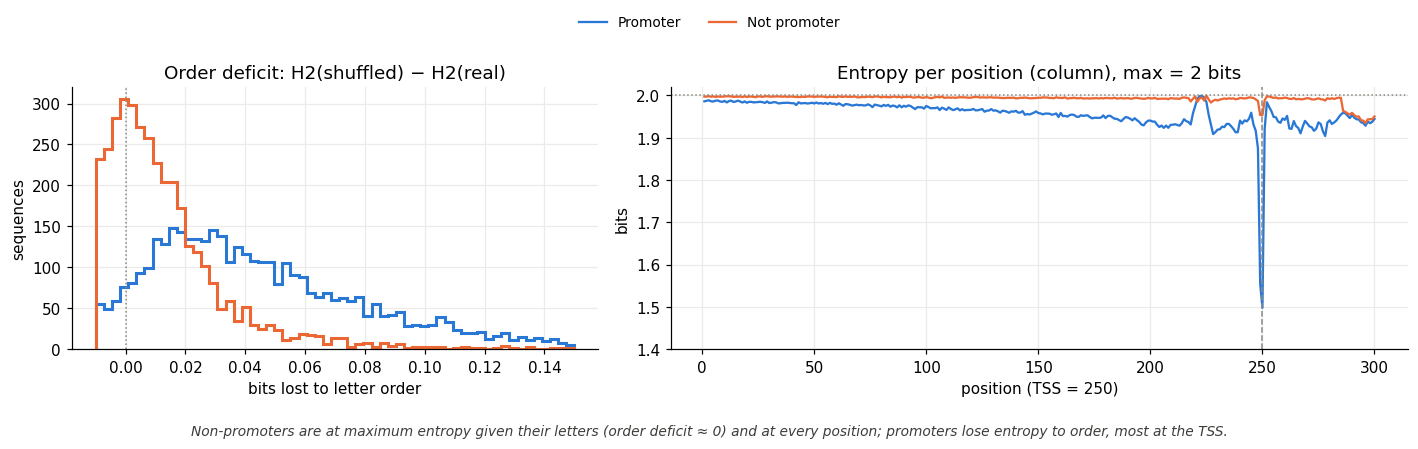

In [28]:
# Per position: entropy of each column (all sequences of a class at that position); max = 2 bits
Lc = np.array([list(x) for x in train.sequence]); yc = train.label.values
def col_entropy(M):
    f = np.clip(np.stack([(M == b).mean(0) for b in "ACGT"]), 1e-12, 1); return -(f * np.log2(f)).sum(0)
col_h = {lab: col_entropy(Lc[yc == lab]) for lab in (0, 1)}
pos = np.arange(1, 301)
fig, ax = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1, 1.4]})
for lab, c, n in CLASSES:
    ax[0].hist(samp.order_deficit[samp.label == lab], bins=np.linspace(-0.01, 0.15, 60), histtype="step", lw=2, color=c, label=n)
    ax[1].plot(pos, col_h[lab], color=c, lw=1.5, label=n)
ax[0].axvline(0, color=GREY, ls=":", lw=1)
ax[0].set(title="Order deficit: H2(shuffled) − H2(real)", xlabel="bits lost to letter order", ylabel="sequences")
ax[1].axhline(2, color=GREY, ls=":", lw=1); tss_line(ax[1])
ax[1].set(title="Entropy per position (column), max = 2 bits", xlabel="position (TSS = 250)", ylabel="bits", ylim=(1.4, 2.02))
leg_top(fig, ax[1])
save(fig, "eda_04b_entropy_max.png",
     "Non-promoters are at maximum entropy given their letters (order deficit ≈ 0) and at every position; promoters lose entropy to order, most at the TSS.")

**Reading it:**
- **Nobody reaches the 4-bit ceiling,** not even random DNA: 300 letters is too short a sample. The fair reference is random-300 (~3.96 bits).
- **Non-promoters:** the order deficit is ~0 (shuffling their letters changes almost nothing). They are at **maximum entropy given their composition**; their only shortfall from random comes from the slightly uneven composition (more G/C) and the kept promoter blocks. The replaced blocks themselves are exactly as random as random 15-mers (checked in Section 16).
- **Promoters** lose clearly more entropy to letter order (motifs, repeats, CpG depletion) on top of their skewed composition.
- **Per position**, non-promoters sit near 2 bits almost everywhere. Promoters drop below it toward the TSS (sharpest at 248–250, the Inr) and around the TATA region.
- **So yes:** the negatives are entropy-maximized wherever they were filled in randomly. That's why entropy is such a strong (and artificial) feature in this dataset (Section 15).

## 9. Position
Promoters are aligned on the TSS (position 250), so position-specific signals should show up as peaks at fixed places. We look at:
- the share of each base at each position, by class
- **information content** per position: IC = 2 − H bits (0 = no preference, 2 = always the same letter). This is the height of a sequence logo.

Top 10 most informative positions, promoters: [250, 249, 248, 278, 228, 267, 238, 239, 229, 277]
Top 10 most informative positions, non-promoters: [296, 295, 294, 297, 299, 298, 292, 293, 300, 291]


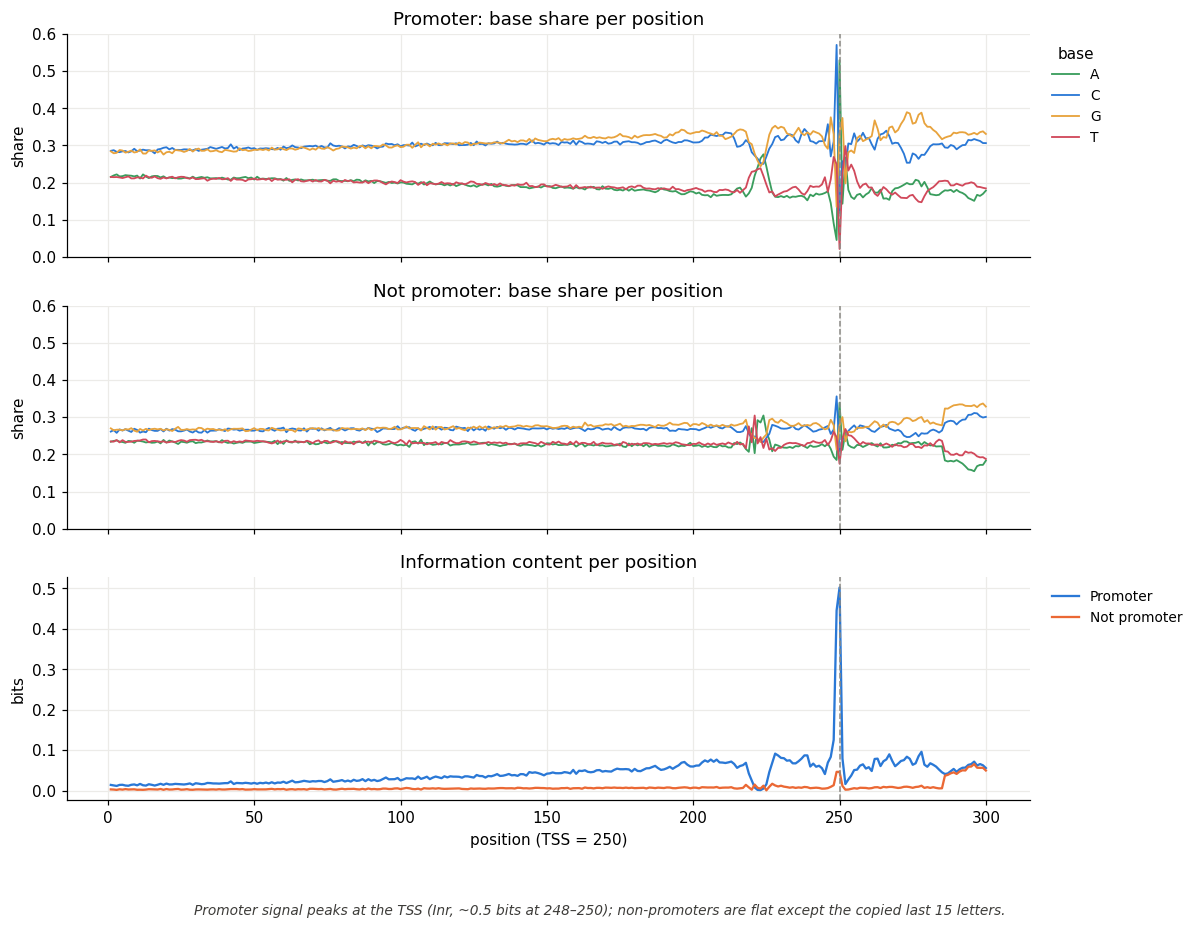

In [29]:
L = np.array([list(s) for s in train.sequence])          # [rows, 300]
y = train.label.values
pos = np.arange(1, 301)
freq = {lab: np.stack([(L[y == lab] == b).mean(0) for b in "ACGT"]) for lab in (0, 1)}   # [4, 300]
def ic(f):
    f = np.clip(f, 1e-9, 1); return 2 + (f * np.log2(f)).sum(0)
fig, ax = plt.subplots(3, 1, figsize=(11, 8.5), sharex=True)
for a, (lab, _, name) in zip(ax[:2], CLASSES):
    for i, b in enumerate("ACGT"): a.plot(pos, freq[lab][i], color=BASE_COLORS[b], lw=1.2, label=b)
    a.set(ylabel="share", title=f"{name}: base share per position", ylim=(0, 0.6)); tss_line(a)
leg_right(ax[0], title="base")
for lab, c, n in CLASSES: ax[2].plot(pos, ic(freq[lab]), color=c, lw=1.5, label=n)
ax[2].set(xlabel="position (TSS = 250)", ylabel="bits", title="Information content per position"); leg_right(ax[2]); tss_line(ax[2])
save(fig, "eda_05_position_bases.png",
     "Promoter signal peaks at the TSS (Inr, ~0.5 bits at 248–250); non-promoters are flat except the copied last 15 letters.")
print("Top 10 most informative positions, promoters:", (pos[np.argsort(-ic(freq[1]))[:10]]).tolist())
print("Top 10 most informative positions, non-promoters:", (pos[np.argsort(-ic(freq[0]))[:10]]).tolist())

Correlation of the two GC profiles across positions: r = 0.602 (all 300), r = 0.867 (positions 1-285)
Correlation of the GC gap with position (1-285): r = 0.761


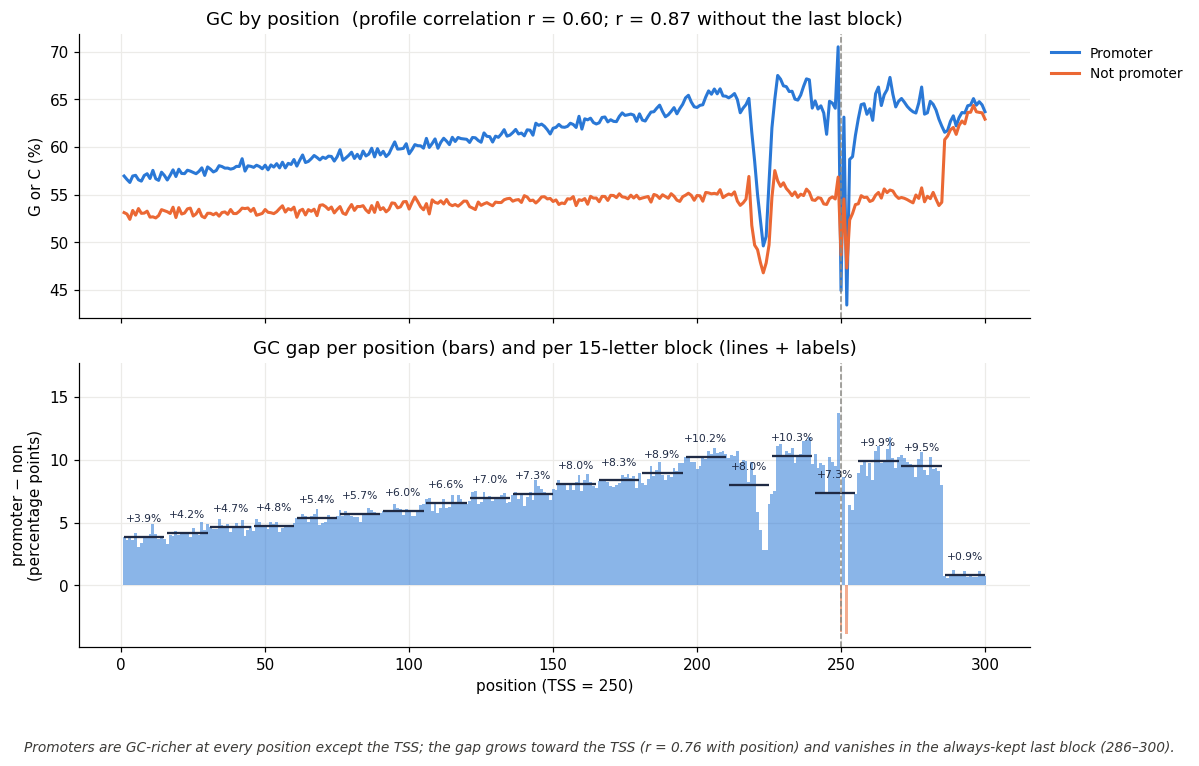

In [30]:
is_gc = np.isin(L, ["G", "C"])
gc_p, gc_n = is_gc[y == 1].mean(0), is_gc[y == 0].mean(0)
diff = (gc_p - gc_n) * 100                                  # percentage points
r_all = np.corrcoef(gc_p, gc_n)[0, 1]
r_rand = np.corrcoef(gc_p[:285], gc_n[:285])[0, 1]          # without the always-kept last block
r_diff_pos = np.corrcoef(pos[:285], diff[:285])[0, 1]
print(f"Correlation of the two GC profiles across positions: r = {r_all:.3f} (all 300), r = {r_rand:.3f} (positions 1-285)")
print(f"Correlation of the GC gap with position (1-285): r = {r_diff_pos:.3f}")

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for lab, c, n in CLASSES: ax[0].plot(pos, (gc_p if lab else gc_n) * 100, color=c, lw=2, label=n)
ax[0].set(ylabel="G or C (%)", title=f"GC by position  (profile correlation r = {r_all:.2f}; r = {r_rand:.2f} without the last block)")
leg_right(ax[0])
ax[1].bar(pos, diff, color=np.where(diff > 0, PROM, NON), width=1, alpha=0.55)
blk = diff.reshape(20, 15).mean(1)
for i, v in enumerate(blk):
    x0 = i * 15 + 1
    ax[1].hlines(v, x0, x0 + 14, color="#1f2a44", lw=1.5)
    ax[1].text(x0 + 7, max(v, 0) + 1.2, f"{v:+.1f}%", ha="center", fontsize=7, color="#1f2a44")
ax[1].set(xlabel="position (TSS = 250)", ylabel="promoter − non\n(percentage points)", ylim=(diff.min() - 1, diff.max() + 4),
          title="GC gap per position (bars) and per 15-letter block (lines + labels)")
for a_ in ax: tss_line(a_)
save(fig, "eda_06_gc_by_position.png",
     f"Promoters are GC-richer at every position except the TSS; the gap grows toward the TSS (r = {r_diff_pos:.2f} with position) and vanishes in the always-kept last block (286–300).")

Promoters carry clear position-specific structure: a GC peak just upstream of the TSS, an A/T dip around −30 (TATA region, positions ~218–225), and a sharp pattern at the TSS itself (Inr). Non-promoters are flat, with information content near zero everywhere, **except a strong echo of the promoter pattern in the last 15 positions** (286–300).

## 10. Core promoter motifs
Known core-promoter elements and where they should sit relative to the TSS:

| Element | Consensus | Expected place | Expected position here |
|---|---|---|---|
| TATA box | `TATAWAW` | −31 to −24 | ~219–226 |
| BRE (upstream) | `SSRCGCC` | right before TATA | ~212–218 |
| Inr | `YYANWYY` (A = TSS) | −2 to +5 | A at 250 → start ~248 |
| DPE | `RGWYV` | +28 to +32 | ~278–282 |
| CCAAT box | `CCAAT` | −60 to −100 | ~150–190 |
| GC box (Sp1) | `GGGCGG` / `CCGCCC` | anywhere upstream | — |

IUPAC: W = A/T, S = C/G, R = A/G, Y = C/T, V = A/C/G, N = any.

In [31]:
IU = {"W": "[AT]", "S": "[CG]", "R": "[AG]", "Y": "[CT]", "V": "[ACG]", "N": "[ACGT]"}
def rx(m): return "".join(IU.get(ch, ch) for ch in m)
MOTIFS = {"TATA box": ("TATAWAW", (219, 226)), "BRE": ("SSRCGCC", (210, 219)), "Inr": ("YYANWYY", (246, 250)),
          "DPE": ("RGWYV", (277, 283)), "CCAAT box": ("CCAAT", (150, 190)), "GC box": ("GGGCGG", None)}
starts = {}
rows = []
for name, (m, win) in MOTIFS.items():
    pat = re.compile(f"(?={rx(m)})")
    for lab, _, cname in CLASSES:
        seqs = train.sequence[train.label == lab]
        st = [[mm.start() + 1 for mm in pat.finditer(s)] for s in seqs]
        starts[(name, lab)] = Counter(p for l in st for p in l)
        anywhere = np.mean([len(l) > 0 for l in st])
        in_win = np.mean([any(win[0] <= p <= win[1] for p in l) for l in st]) if win else np.nan
        rows.append({"motif": name, "consensus": m, "class": cname, "anywhere": anywhere, "in expected window": in_win})
mt = pd.DataFrame(rows).pivot(index=["motif", "consensus"], columns="class", values=["anywhere", "in expected window"])
(mt * 100).round(1)

anywhere          in expected window         
class               Not promoter Promoter       Not promoter Promoter
motif     consensus                                                  
BRE       SSRCGCC           24.4     37.0                1.2      2.5
CCAAT box CCAAT             21.7     18.0                4.3      5.9
DPE       RGWYV             99.8     99.3               15.6     15.6
GC box    GGGCGG            22.3     37.4                NaN      NaN
Inr       YYANWYY           85.5     73.2                5.6      8.2
TATA box  TATAWAW            6.2      5.0                1.4      1.8

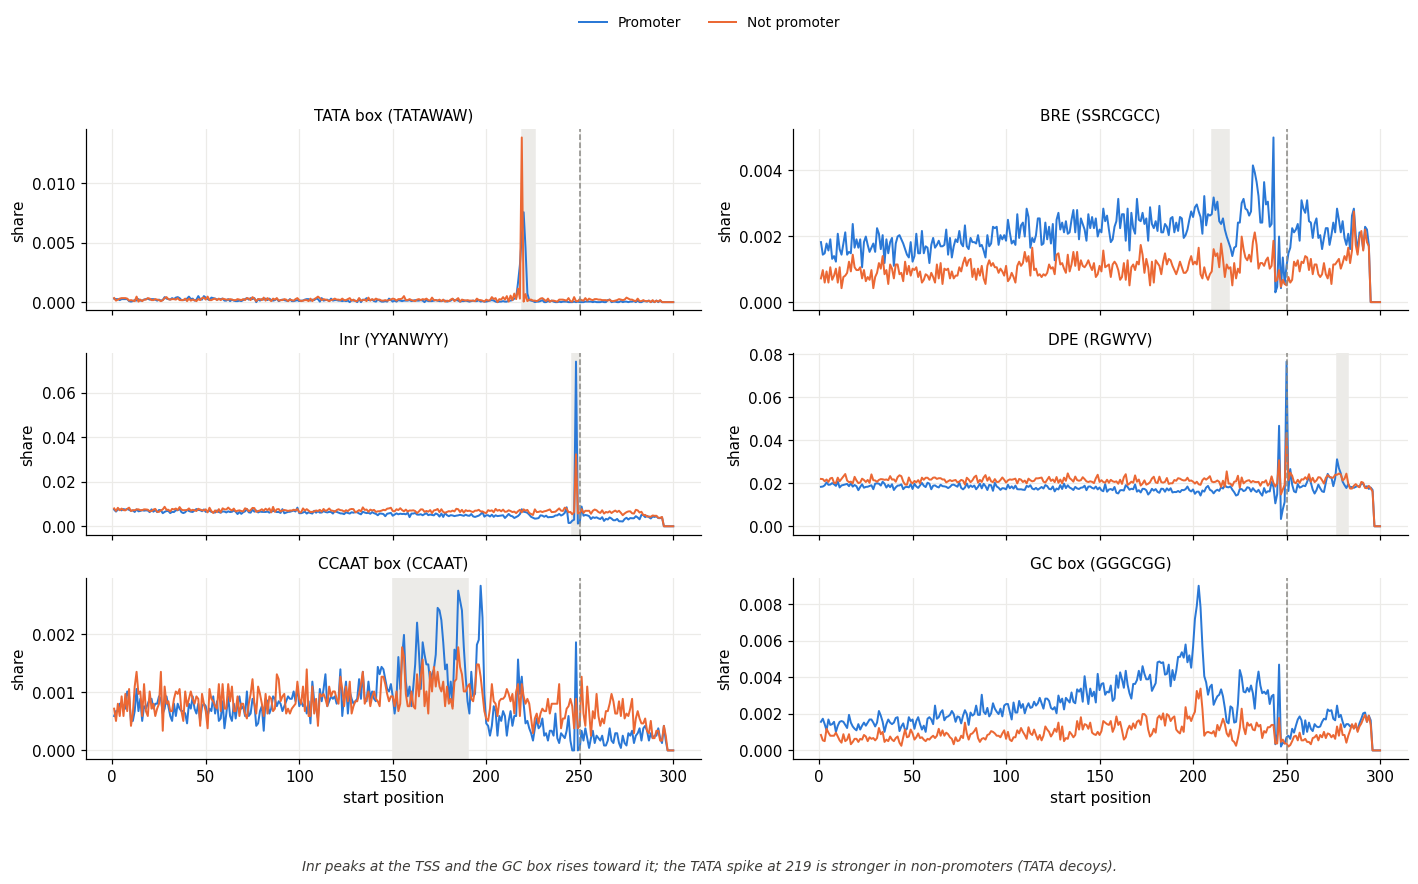

In [32]:
fig, axs = plt.subplots(3, 2, figsize=(13, 8), sharex=True)
for a, (name, (m, win)) in zip(axs.ravel(), MOTIFS.items()):
    for lab, c, n in CLASSES:
        cnt = starts[(name, lab)]; tot = (train.label == lab).sum()
        a.plot(pos, [cnt.get(p, 0) / tot for p in pos], color=c, lw=1.3, label=n)
    if win: a.axvspan(*win, color="#ecebe8")
    tss_line(a); a.set_title(f"{name} ({m})", fontsize=10); a.set_ylabel("share")
leg_top(fig, axs[0, 0]); axs[-1, 0].set_xlabel("start position"); axs[-1, 1].set_xlabel("start position")
save(fig, "eda_07_motif_positions.png",
     "Inr peaks at the TSS and the GC box rises toward it; the TATA spike at 219 is stronger in non-promoters (TATA decoys).")

- **TATA box** is rare (~5% of promoters, as expected: most human promoters are TATA-less). It peaks at ~220 in promoters, and non-promoters show an even sharper spike at exactly 219.
- **Inr** peaks exactly at the TSS (start 248, A at 250) in promoters: the strongest single positional signal in the data (information content 0.5 bits at 248–250, Section 9).
- **DPE** (`RGWYV`, a short and loose pattern) is everywhere (~99% of sequences). The spike is at the TSS, not at +28…+32, with only a weak bump at ~277. Too unspecific to be useful on its own.
- **GC box** is enriched in promoters and rises towards the TSS (peak ~200). **CCAAT** is slightly enriched at ~150–200, as expected.
- Non-promoters show a flat background, a weaker echo of the promoter peaks (from kept promoter blocks), and **a TATA spike at exactly 219, higher than in promoters**. Section 16 explains it: a second kind of negative.

## 11. k-mers
This matters for tokenization: how many of the 4^k possible k-mers actually occur? How skewed are their frequencies (Zipf)? Which 6-mers are most class-specific?

In [33]:
big = "|".join(train.sequence)
rows, counts = [], {}
for k in range(1, 9):
    c = Counter(big[i:i+k] for i in range(len(big) - k + 1)); c = Counter({x: v for x, v in c.items() if "|" not in x and "N" not in x})
    counts[k] = c
    per_seq = train.sequence.head(3000).map(lambda s: len({s[i:i+k] for i in range(301 - k)})).mean()
    rows.append({"k": k, "possible (4^k)": 4**k, "observed": len(c), "coverage": len(c) / 4**k,
                 "unique per sequence (mean)": round(per_seq, 1), "singletons": sum(v == 1 for v in c.values())})
pd.DataFrame(rows)

,k,possible (4^k),observed,coverage,unique per sequence (mean),singletons
0,1,4,4,1.0,4.0,0
1,2,16,16,1.0,16.0,0
2,3,64,64,1.0,60.0,0
3,4,256,256,1.0,155.1,0
4,5,1024,1024,1.0,234.5,0
5,6,4096,4096,1.0,271.0,0
6,7,16384,16384,1.0,284.1,0
7,8,65536,65536,1.0,288.3,0


,most promoter-enriched,log2FC (+),most non-promoter-enriched,log2FC (-)
0,CCCGCC,1.34,ATATCG,-3.04
1,GGCGGG,1.30,TATACG,-3.02
2,GGGCGG,1.30,ACGATA,-2.97
3,CCGCCC,1.29,CGTATA,-2.97
4,CCCCGC,1.27,TACGAT,-2.92
5,GGGGCG,1.25,CGATAT,-2.90
6,CGCCCC,1.25,ATACGA,-2.87
7,GCGGGG,1.25,TCGTAT,-2.86
8,CCTCCC,1.21,TATCGT,-2.85
9,GCCCCG,1.17,TCGATA,-2.85


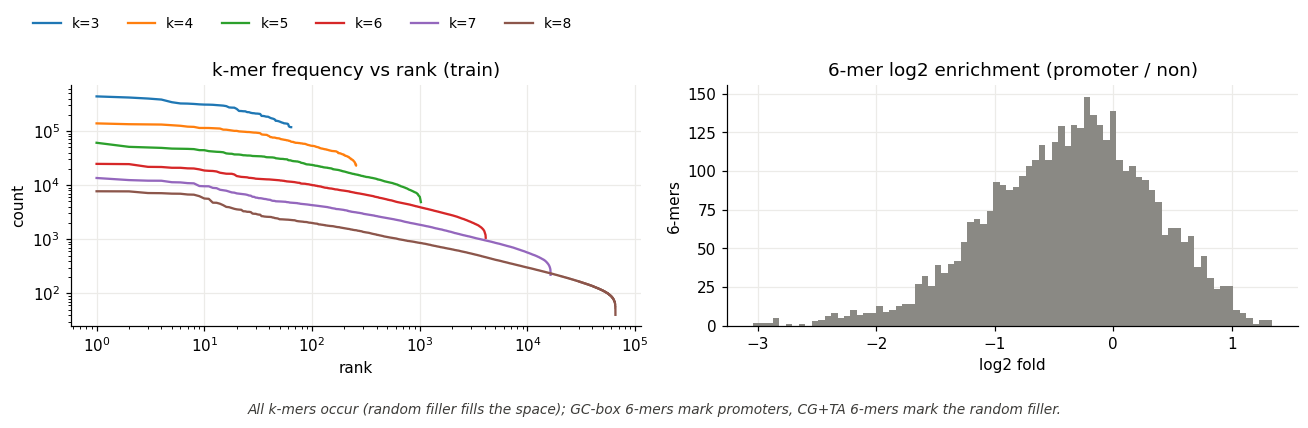

In [34]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for k in (3, 4, 5, 6, 7, 8):
    v = np.sort(np.array(list(counts[k].values())))[::-1]; ax[0].loglog(np.arange(1, len(v) + 1), v, label=f"k={k}")
ax[0].set(title="k-mer frequency vs rank (train)", xlabel="rank", ylabel="count"); leg_top(fig, ax[0], "left")
# enrichment: log2 of (share of promoter 6-mers / share of non-promoter 6-mers), pseudo-count 1
def kcount(seqs, k=6):
    c = Counter()
    for s in seqs: c.update(s[i:i+k] for i in range(len(s) - k + 1))
    return c
c1, c0 = kcount(train.sequence[train.label == 1]), kcount(train.sequence[train.label == 0])
allk = ["".join(p) for p in product("ACGT", repeat=6)]
n1, n0 = sum(c1.values()), sum(c0.values())
lfc = pd.Series({k: np.log2(((c1[k] + 1) / n1) / ((c0[k] + 1) / n0)) for k in allk}).sort_values()
ax[1].hist(lfc, bins=80, color=GREY); ax[1].set(title="6-mer log2 enrichment (promoter / non)", xlabel="log2 fold", ylabel="6-mers")
save(fig, "eda_08_kmers.png",
     "All k-mers occur (random filler fills the space); GC-box 6-mers mark promoters, CG+TA 6-mers mark the random filler.")
gcf = lambda k: sum(ch in "GC" for ch in k)
pd.DataFrame({"most promoter-enriched": lfc.index[::-1][:12], "log2FC (+)": lfc.values[::-1][:12].round(2),
              "most non-promoter-enriched": lfc.index[:12], "log2FC (-)": lfc.values[:12].round(2)})

In [35]:
# Do enrichment and CpG content line up? (6-mers containing CG vs not)
has_cg = pd.Series({k: "CG" in k for k in lfc.index})
print("mean log2FC, 6-mers containing CG:", lfc[has_cg].mean().round(3), "| without CG:", lfc[~has_cg].mean().round(3))
print("Spearman(log2FC, GC count of the 6-mer):", round(stats.spearmanr(lfc.values, [gcf(k) for k in lfc.index])[0], 3))

mean log2FC, 6-mers containing CG: -0.554 | without CG: -0.303
Spearman(log2FC, GC count of the 6-mer): 0.558


- **Every possible k-mer occurs, even all 65,536 8-mers, and none occurs only once.** For real human DNA this would be unusual (CpG-containing 8-mers are rare). Here the random filler in the negatives covers the whole space. A k-mer tokenizer therefore never meets an unseen token, but for k ≥ 7 most k-mers are seen in only a handful of contexts.
- Within one sequence, 6-mers are almost all different (271 unique of 295), so counts are mostly 0/1 per sequence. That's why TF-IDF and counts behave similarly at k = 6.
- The most promoter-enriched 6-mers are GC-box / ETS-like (`GGAA`, `CCGGAA`, `GGGCGG`). The most non-promoter-enriched ones mix `CG` with `TA` (`ATATCG`, `CGTATA`, ~8× more common in negatives). Real genomic DNA rarely has these because both dinucleotides are depleted, so they come from the random filler (Section 16). Enrichment correlates with the 6-mer's GC count (Spearman 0.56).

## 12. Split consistency
The models are tuned on dev and reported on test, so all three splits should come from the same distribution. Two-sample Kolmogorov–Smirnov tests vs. train, per class:

In [36]:
feats = ["gc", "gc_skew", "cpg_oe", "entropy_k2", "longest_homopolymer"]
rows = []
for f in feats:
    for lab, _, cname in CLASSES:
        for n in ("dev", "test"):
            a, b = train[f][train.label == lab], splits[n][f][splits[n].label == lab]
            ks = stats.ks_2samp(a, b)
            rows.append({"feature": f, "class": cname, "split": n, "train mean": round(a.mean(), 3), "split mean": round(b.mean(), 3),
                         "KS stat": round(ks.statistic, 3), "p": round(ks.pvalue, 3)})
pd.DataFrame(rows)

,feature,class,split,train mean,split mean,KS stat,p
0,gc,Promoter,dev,0.612,0.611,0.010,0.970
1,gc,Promoter,test,0.612,0.611,0.008,0.991
2,gc,Not promoter,dev,0.544,0.543,0.016,0.495
3,gc,Not promoter,test,0.544,0.545,0.011,0.914
4,gc_skew,Promoter,dev,0.015,0.017,0.018,0.372
5,gc_skew,Promoter,test,0.015,0.010,0.023,0.112
6,gc_skew,Not promoter,dev,0.015,0.013,0.023,0.133
7,gc_skew,Not promoter,test,0.015,0.015,0.013,0.762
8,cpg_oe,Promoter,dev,0.640,0.633,0.016,0.499
9,cpg_oe,Promoter,test,0.640,0.645,0.014,0.687


KS statistics are tiny everywhere (≈0.01–0.03). With 3,000 rows per class, only large shifts would show up, and none does: dev and test look like train.

## 13. Correlations
Pearson r between per-sequence features and the label (point-biserial), plus Spearman as a check. Then: which features are redundant with each other?

In [37]:
def feature_frame(d):
    f = pd.DataFrame(index=d.index)
    for b in "ACGT": f[f"frac_{b}"] = d.sequence.str.count(b) / 300
    for c in ["gc", "gc_skew", "at_skew", "gc_skew_up", "gc_skew_down", "gc_skew_switch", "at_skew_up", "at_skew_down", "abs_gc_skew", "abs_at_skew", "cpg_oe", "entropy_k1", "entropy_k2", "entropy_k3", "longest_homopolymer"]: f[c] = d[c]
    f["has_tandem_repeat"] = d.has_tandem_repeat.astype(int)
    f["cg_count"] = d.sequence.str.count("(?=CG)")
    f["gc_first50"] = d.sequence.str[:50].map(lambda s: (s.count("G") + s.count("C")) / 50)
    f["gc_tss_200_260"] = d.sequence.str[199:260].map(lambda s: (s.count("G") + s.count("C")) / 61)
    f["gc_last15"] = d.sequence.str[-15:].map(lambda s: (s.count("G") + s.count("C")) / 15)
    f["tata_box"] = d.sequence.str[215:230].str.contains(rx("TATAWAW")).astype(int)
    f["inr_at_tss"] = d.sequence.str[245:252].str.contains(rx("YYANWYY")).astype(int)
    f["gc_box"] = d.sequence.str.contains("GGGCGG|CCGCCC").astype(int)
    f["ccaat"] = d.sequence.str.contains("CCAAT|ATTGG").astype(int)
    return f
F = feature_frame(train)
corr = pd.concat([F, train.label], axis=1).corr()
r = corr["label"].drop("label").sort_values(key=abs, ascending=False)
pd.DataFrame({"pearson r": r.round(3), "spearman": F.corrwith(train.label, method="spearman")[r.index].round(3)})

,pearson r,spearman
entropy_k3,-0.592,-0.701
entropy_k2,-0.564,-0.682
entropy_k1,-0.477,-0.517
gc_tss_200_260,0.358,0.365
gc,0.334,0.342
cpg_oe,-0.325,-0.293
frac_A,-0.297,-0.315
frac_T,-0.287,-0.310
frac_G,0.262,0.241
frac_C,0.257,0.243


Redundant pairs |r| > 0.8:
entropy_k3      entropy_k2        0.990
entropy_k2      entropy_k1        0.975
entropy_k3      entropy_k1        0.948
gc_skew_up      gc_skew           0.939
at_skew         at_skew_up        0.922
gc              frac_T           -0.879
                frac_A           -0.869
gc_skew_down    gc_skew_switch    0.841
gc              cg_count          0.828
gc_tss_200_260  gc                0.807
cpg_oe          cg_count          0.807
dtype: float64


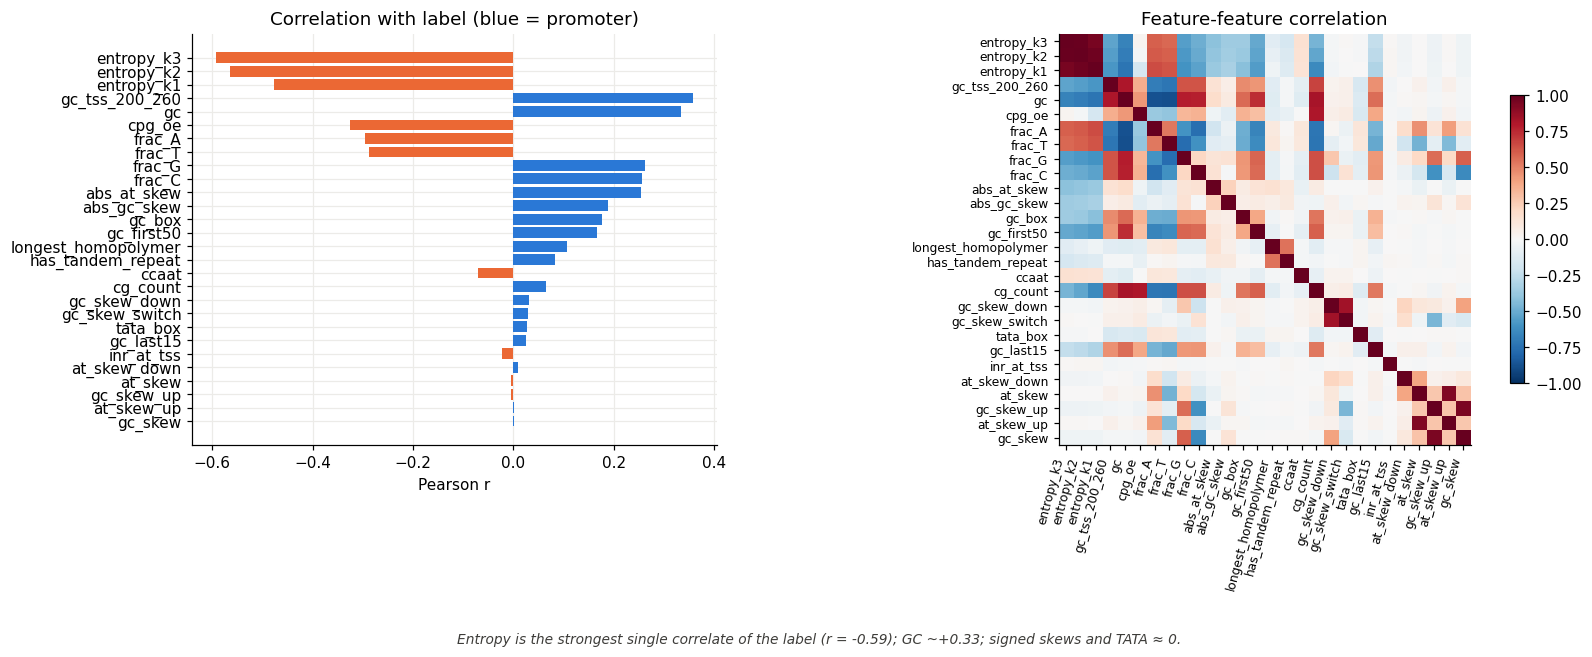

In [38]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 1.5]})
ax[0].barh(r.index[::-1], r.values[::-1], color=[PROM if v > 0 else NON for v in r.values[::-1]])
ax[0].set(title="Correlation with label (blue = promoter)", xlabel="Pearson r")
cm = corr.loc[r.index, r.index]
im = ax[1].imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1); ax[1].grid(False)
ax[1].set_xticks(range(len(cm))); ax[1].set_xticklabels(cm.columns, rotation=75, ha="right", fontsize=8)
ax[1].set_yticks(range(len(cm))); ax[1].set_yticklabels(cm.columns, fontsize=8)
ax[1].set_title("Feature-feature correlation"); fig.colorbar(im, ax=ax[1], shrink=0.7)
save(fig, "eda_09_correlations.png",
     f"Entropy is the strongest single correlate of the label (r = {r.iloc[0]:.2f}); GC ~+0.33; signed skews and TATA ≈ 0.")
pairs = cm.where(np.triu(np.ones(cm.shape), 1).astype(bool)).stack()
print("Redundant pairs |r| > 0.8:"); print(pairs[pairs.abs() > 0.8].sort_values(key=abs, ascending=False).round(3))

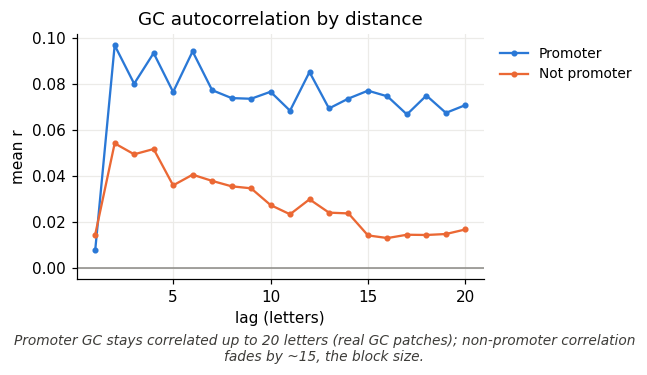

In [39]:
# Is there short-range order? Correlation of GC at position i with GC at i+d (lag), by class
lags = range(1, 21)
fig, ax = plt.subplots(figsize=(6, 3.4))
for lab, c, n in CLASSES:
    g = is_gc[y == lab].astype(float)[:8000]; g = g - g.mean(0)
    ac = [np.mean([np.corrcoef(g[:, i], g[:, i + d])[0, 1] for i in range(0, 300 - d, 5)]) for d in lags]
    ax.plot(list(lags), ac, marker="o", ms=3, color=c, label=n)
ax.axhline(0, color=GREY, lw=1); ax.set(title="GC autocorrelation by distance", xlabel="lag (letters)", ylabel="mean r"); leg_right(ax)
save(fig, "eda_10_autocorrelation.png",
     "Promoter GC stays correlated up to 20 letters (real GC patches); non-promoter correlation fades by ~15, the block size.")

Entropy is the single feature most correlated with the label (stronger than GC). GC autocorrelation: at lag 1 it's ~0 in both classes (CpG and GpC depletion makes direct G/C neighbours less common than chance). From lag 2 to 20, promoters keep a steady r ≈ 0.07–0.09, because real GC-rich regions come in patches. Non-promoters start lower (~0.05) and fade to ~0.015 by lag 15, which is the 15-letter block size: correlation only survives *inside* a kept block, while random blocks have none.

## 14. Low-dimensional view
Each sequence becomes a 64-dimensional profile of 3-mer frequencies. PCA (linear) and t-SNE (nonlinear) on a sample show whether the classes separate without any training.

explained variance, first 5 PCs: [0.224 0.075 0.066 0.049 0.04 ]


corr(PC1, GC) = 0.992 | corr(PC1, label) = 0.389


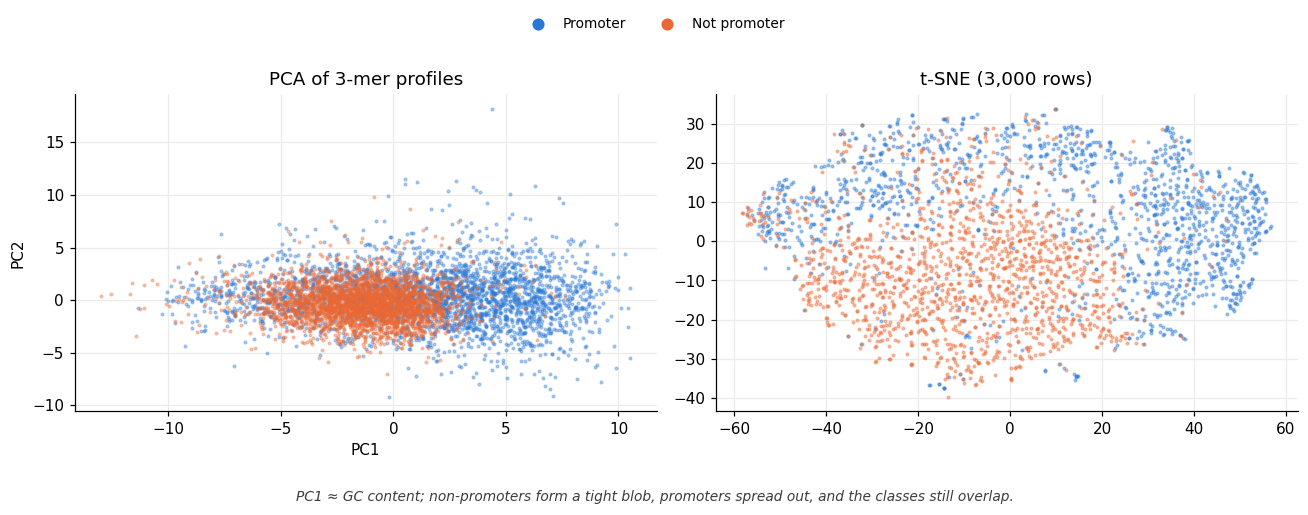

In [40]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import StandardScaler
samp = train.sample(6000, random_state=0)
X3 = CountVectorizer(analyzer="char", ngram_range=(3, 3), lowercase=False).fit_transform(samp.sequence).toarray().astype(float)
X3 = StandardScaler().fit_transform(X3 / X3.sum(1, keepdims=True))
pca = PCA(10, random_state=0).fit(X3); Z = pca.transform(X3)
print("explained variance, first 5 PCs:", pca.explained_variance_ratio_[:5].round(3))
T = TSNE(2, random_state=0, init="pca", perplexity=40).fit_transform(Z[:3000])
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for lab, c, n in CLASSES:
    m = samp.label.values == lab
    ax[0].scatter(Z[m, 0], Z[m, 1], s=3, alpha=0.35, color=c, label=n)
    ax[1].scatter(T[m[:3000], 0], T[m[:3000], 1], s=3, alpha=0.4, color=c, label=n)
ax[0].set(title="PCA of 3-mer profiles", xlabel="PC1", ylabel="PC2"); ax[1].set(title="t-SNE (3,000 rows)")
ax[0].legend(); leg_top(fig, ax[0], markerscale=4)
save(fig, "eda_11_pca_tsne.png",
     "PC1 ≈ GC content; non-promoters form a tight blob, promoters spread out, and the classes still overlap.")
print("corr(PC1, GC) =", round(np.corrcoef(Z[:, 0], samp.gc)[0, 1], 3), "| corr(PC1, label) =", round(np.corrcoef(Z[:, 0], samp.label)[0, 1], 3))

PC1 is essentially GC content (r = 0.99). Non-promoters form a tight blob (they all look alike), and promoters spread out along PC1. t-SNE separates the classes more clearly than PCA, but a band of promoters still sits inside the non-promoter cloud. The classes separate partially but overlap a lot, so composition alone isn't enough.

## 15. Simple-feature baselines
How far can the handcrafted EDA features go? Each feature alone (ROC-AUC on dev), then a logistic regression on all of them. Fitted on train, scored on **dev only**.

In [41]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, matthews_corrcoef
from sklearn.pipeline import make_pipeline
Fd = feature_frame(dev)
single = pd.Series({c: max(roc_auc_score(dev.label, Fd[c]), 1 - roc_auc_score(dev.label, Fd[c])) for c in F.columns}).sort_values(ascending=False)
print("Single-feature dev ROC-AUC (direction-free):"); print(single.round(3).head(8))
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(F, train.label)
p = clf.predict_proba(Fd)[:, 1]
print(f"\nLogReg on all {F.shape[1]} handcrafted features -> dev ROC-AUC {roc_auc_score(dev.label, p):.3f}, MCC {matthews_corrcoef(dev.label, p >= 0.5):.3f}")
for c in ["gc", "entropy_k2"]:
    m = make_pipeline(StandardScaler(), LogisticRegression()).fit(F[[c]], train.label)
    print(f"{c:<11} alone -> dev MCC {matthews_corrcoef(dev.label, m.predict(Fd[[c]])):.3f}")

Single-feature dev ROC-AUC (direction-free):
entropy_k3        0.911
entropy_k2        0.901
entropy_k1        0.809
gc_tss_200_260    0.708
gc                0.697
frac_A            0.680
frac_T            0.680
cpg_oe            0.665
dtype: float64

LogReg on all 28 handcrafted features -> dev ROC-AUC 0.941, MCC 0.752
gc          alone -> dev MCC 0.337
entropy_k2  alone -> dev MCC 0.641


Dinucleotide/trinucleotide entropy alone reaches dev ROC-AUC ≈ 0.90, and its MCC (~0.64) is about double that of GC alone. A logistic regression on ~26 handcrafted features gets MCC ≈ 0.75, close to the k-mer logistic regression (step 2: 0.785) and without any k-mers. Most of that power comes from *randomness detection*, not promoter biology.

## 16. How were the negatives made?
Sections 7, 8, 10 and 11 all point the same way: non-promoters look **random** (CpG o/e ≈ 0.85, entropy near the maximum) but carry **sharp promoter-like spikes at fixed positions**.

The DNABERT / DeePromoter recipe for "hard" negatives: take a real promoter, cut it into **20 blocks of 15 letters**, keep **8 blocks**, and replace the other **12 with random DNA**.

**Test:** index every 15-letter block of every promoter (all splits) by (block number, block text). For each non-promoter, count how many of its 20 blocks match the *same* promoter at the *same* block number.

In [42]:
all_prom = pd.concat([d.assign(split=n) for n, d in splits.items()]).query("label == 1").reset_index(drop=True)
index = defaultdict(list)
for i, s in enumerate(all_prom.sequence):
    for b in range(20): index[(b, s[b*15:(b+1)*15])].append(i)

def best_parent(s, exclude=None):
    votes = Counter()
    for b in range(20):
        for i in index.get((b, s[b*15:(b+1)*15]), ()):
            if i != exclude: votes[i] += 1
    return votes.most_common(1)[0] if votes else (-1, 0)

t0 = time.time()
neg = pd.concat([d.assign(split=n) for n, d in splits.items()]).query("label == 0").reset_index(drop=True)
neg[["parent", "shared_blocks"]] = pd.DataFrame([best_parent(s) for s in neg.sequence])
print(f"done in {time.time()-t0:.0f}s")
print("Non-promoters: blocks shared with their best-matching promoter")
print(neg.shared_blocks.value_counts().sort_index().to_frame("rows").assign(share=lambda t: (t.rows / t.rows.sum()).round(3)))

done in 0s
Non-promoters: blocks shared with their best-matching promoter
                rows  share
shared_blocks              
0               2944  0.099
1                100  0.003
2                  5  0.000
3                  1  0.000
8              26533  0.896
20                15  0.001


In [43]:
# Control: the same test on promoters (excluding the promoter itself)
pr_sample = all_prom.sample(3000, random_state=0)
ctrl = pd.Series([best_parent(s, exclude=i)[1] for i, s in zip(pr_sample.index, pr_sample.sequence)])
print("Promoters vs. their best OTHER promoter:"); print(ctrl.value_counts().sort_index().to_frame("rows").T)

Promoters vs. their best OTHER promoter:
        0    1   2   3   4   5   6   7   8   9   11  12  14  15  16  17  18  \
rows  2717  203  20   7   2   6   2   2   3   1   2   2   1   1   1   2   2   

      20  
rows  26  


kept share per block: [0.37, 0.37, 0.36, 0.37, 0.37, 0.37, 0.37, 0.37, 0.37, 0.37, 0.38, 0.37, 0.37, 0.37, 0.37, 0.37, 0.37, 0.37, 0.36, 1.0]
replaced-block base shares: {'A': 0.25, 'C': 0.25, 'G': 0.25, 'T': 0.25} | CpG o/e of replaced blocks ~ random


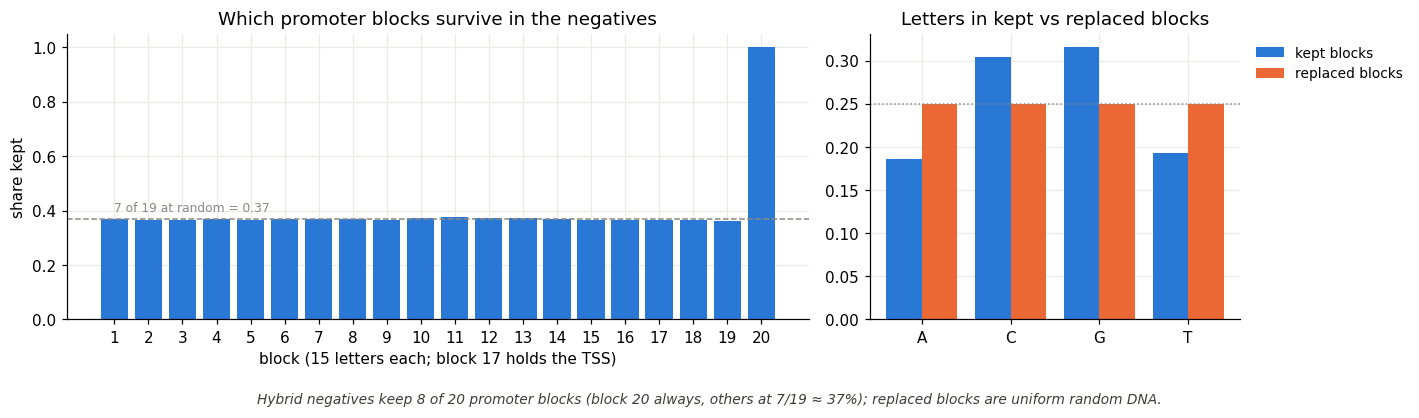

In [44]:
# Which blocks are kept, and what do the replaced blocks look like?
fam = neg[neg.shared_blocks == 8]
kept = np.zeros(20); kept_letters, new_letters = Counter(), Counter()
for s, pi in zip(fam.sequence, fam.parent):
    p = all_prom.sequence[pi]
    for b in range(20):
        blk = s[b*15:(b+1)*15]
        if blk == p[b*15:(b+1)*15]: kept[b] += 1; kept_letters.update(blk)
        else: new_letters.update(blk)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [2, 1]})
ax[0].bar(np.arange(1, 21), kept / len(fam), color=PROM)
ax[0].axhline(7 / 19, color=GREY, ls="--", lw=1); ax[0].text(1, 7/19 + 0.03, "7 of 19 at random = 0.37", fontsize=8, color=GREY)
ax[0].set(xticks=range(1, 21), xlabel="block (15 letters each; block 17 holds the TSS)", ylabel="share kept", title="Which promoter blocks survive in the negatives")
tot_k, tot_n = sum(kept_letters.values()), sum(new_letters.values())
ax[1].bar(np.arange(4) - 0.2, [kept_letters[b] / tot_k for b in "ACGT"], 0.4, color=PROM, label="kept blocks")
ax[1].bar(np.arange(4) + 0.2, [new_letters[b] / tot_n for b in "ACGT"], 0.4, color=NON, label="replaced blocks")
ax[1].axhline(0.25, color=GREY, ls=":", lw=1); ax[1].set(xticks=range(4), xticklabels=list("ACGT"), title="Letters in kept vs replaced blocks"); leg_right(ax[1])
save(fig, "eda_12_negative_construction.png",
     "Hybrid negatives keep 8 of 20 promoter blocks (block 20 always, others at 7/19 ≈ 37%); replaced blocks are uniform random DNA.")
print("kept share per block:", (kept / len(fam)).round(2).tolist())
print("replaced-block base shares:", {b: round(new_letters[b] / tot_n, 3) for b in "ACGT"}, "| CpG o/e of replaced blocks ~ random")

In [45]:
# Leakage through parents: a negative in one split built from a promoter in another split
has_parent = neg[neg.shared_blocks >= 8].copy()
has_parent["parent_split"] = all_prom.split.values[has_parent.parent.values]
ct = pd.crosstab(has_parent.split, has_parent.parent_split, margins=True)
print("rows = split of the negative, columns = split of its parent promoter"); ct

rows = split of the negative, columns = split of its parent promoter


parent_split,dev,test,train,All
split,,,,
dev,244,272,2149,2665
test,274,260,2091,2625
train,2089,2134,17035,21258
All,2607,2666,21275,26548


In [46]:
# The ~10% of negatives with no parent: a different recipe?
neg["family"] = np.where(neg.shared_blocks >= 8, "8-block hybrid", "no parent (0-3 blocks)")
neg["gc"] = (neg.sequence.str.count("G") + neg.sequence.str.count("C")) / 300
neg["cpg_oe"] = neg.sequence.map(cpg_oe); neg["entropy_k2"] = neg.sequence.map(lambda s: shannon(s, 2))
neg["tata_at_219"] = neg.sequence.str[218:225].str.match(rx("TATAWAW"))
neg["tata_anywhere"] = neg.sequence.str.contains(rx("TATAWAW"))
fam_tab = neg.groupby("family")[["gc", "cpg_oe", "entropy_k2", "tata_at_219", "tata_anywhere"]].mean()
fam_tab["rows"] = neg.family.value_counts()
prm = pd.concat(splits.values()).query("label == 1")
fam_tab.loc["real promoters"] = [prm.gc.mean(), prm.cpg_oe.mean(), prm.entropy_k2.mean(),
                                 prm.sequence.str[218:225].str.match(rx("TATAWAW")).mean(), prm.sequence.str.contains(rx("TATAWAW")).mean(), len(prm)]
fam_tab.round(3)

,gc,cpg_oe,entropy_k2,tata_at_219,tata_anywhere,rows
family,,,,,,
8-block hybrid,0.548,0.873,3.926,0.000,0.051,26548.0
no parent (0-3 blocks),0.508,0.475,3.812,0.134,0.158,3050.0
real promoters,0.612,0.640,3.732,0.006,0.052,29598.0


In [47]:
# Entropy check (Section 8b): are the replaced blocks maximally random?
rng = np.random.default_rng(3)
# Per block (hybrid negatives): pooled letter-pair entropy of kept vs replaced blocks, vs random 15-mers
fam8 = neg[neg.shared_blocks == 8].sample(4000, random_state=0)
kept_b, repl_b = [], []
for x, pi in zip(fam8.sequence, fam8.parent):
    par = all_prom.sequence[pi]
    for b in range(19):                      # block 20 is always kept; skip it to compare like with like
        (kept_b if x[b*15:(b+1)*15] == par[b*15:(b+1)*15] else repl_b).append(x[b*15:(b+1)*15])
def pooled_h2(blocks):
    c = Counter(bl[i:i+2] for bl in blocks for i in range(14)); n = sum(c.values()); pr = np.array(list(c.values())) / n
    return float(-(pr * np.log2(pr)).sum())
rand_blocks = ["".join(rng.choice(list("ACGT"), 15)) for _ in range(20000)]
print("Pooled dinucleotide entropy of 15-letter blocks (max 4 bits):")
print(f"  replaced blocks: {pooled_h2(repl_b):.4f} | random 15-mers: {pooled_h2(rand_blocks):.4f} | kept (promoter) blocks: {pooled_h2(kept_b):.4f}")

Pooled dinucleotide entropy of 15-letter blocks (max 4 bits):
  replaced blocks: 4.0000 | random 15-mers: 4.0000 | kept (promoter) blocks: 3.8927


**Result:** the hypothesis holds.
- Most non-promoters share **exactly 8 of 20** blocks with one real promoter, while real promoters almost never share more than 1–2 blocks with another promoter. This isn't chance.
- **The last block (286–300) is always kept;** the other 7 kept blocks are spread evenly over blocks 1–19. That explains the "copied last 15 letters" and the single-position motif spikes (e.g. the TATA spike at 219).
- **The replaced blocks are uniform random DNA** (~25% each letter). That explains the high CpG o/e, the near-maximum entropy and the enriched `CG+TA` 6-mers.
- **There is a second kind of negative.** The ~10% with no parent are *not* random-looking (lower CpG o/e ~0.47, lower entropy), and ~13% of them have a TATA box at **exactly position 219**, vs. 0.6% of real promoters. They match the DeePromoter recipe for TATA promoters: real non-promoter genomic fragments that contain a TATA box at the promoter's TATA position. **This is the TATA spike at 219** from Section 10 (and Alejandro's EDA), and it explains why a model learns "TATA at the TATA position → not promoter".
- **Leakage through parents:** most hybrid negatives in dev and test were built from a promoter that sits in **train** (e.g. ~2,100 of ~2,600 test hybrids). So 8 of the 20 blocks of those test negatives appear, at the same positions, in a train *promoter*. That probably makes the task slightly *harder* for memorizing models (the shared blocks point to "promoter"), not easier, but it means test negatives aren't independent of train.

**What this means:** the task isn't "promoter vs. other human DNA". It's **"real promoter vs. a promoter with 60% of it replaced by random letters."** A model can win by detecting *randomness* (entropy, CpG, `CG`-next-to-`TA` k-mers) as much as by detecting promoter biology. This matters when we read the model results and the Integrated Gradients plots (e.g. "pushes toward non-promoter at the TATA area").

## 16b. Mutation lens: is it relevant?
Our README motivates promoter models with **variant interpretation**: score the normal and the mutated sequence, then compare. For that, the model has to react to **single-letter changes** in a biologically sensible way. Three EDA-level checks:

1. **CpG sites are mutation hotspots.** Methylated C in a CpG deaminates to T (C→T / G→A), about 10–50× faster than other substitutions. That's *why* the human genome is CpG-depleted (Section 7). Promoters, especially CpG islands, are where unmethylated, CpG-dense DNA survives.
2. **The deamination footprint.** CpG loss should leave extra TpG and CpA behind. Real DNA shows (TG+CA) o/e > 1, while random filler shouldn't.
3. **How much does one mutation move the features that separate the classes?** If the label can mostly be read from *randomness* (entropy), a single SNV barely changes it, so a model leaning on it would be blind to real variants.

In [48]:
# 1. CpG hotspots per sequence, and 2. deamination footprint, per class (and per negative family)
for d in splits.values(): d["cpg_sites"] = d.sequence.str.count("(?=CG)")
fp = train.groupby("label").agg(cpg_sites=("cpg_sites", "mean"))
fp["CG o/e"] = [oe.loc["CG", "Not promoter"], oe.loc["CG", "Promoter"]]
fp["(TG+CA)/2 o/e"] = [(oe.loc["TG", c] + oe.loc["CA", c]) / 2 for c in ["Not promoter", "Promoter"]]
fp.index = ["Not promoter", "Promoter"]
print(fp.round(3)); print("uniform random: CG o/e 1.00, (TG+CA)/2 o/e 1.00")
pr = train[train.label == 1]
isl = pr.cpg_oe > 0.6
print(f"\nPromoters: CpG-island-like (o/e > 0.6) {isl.mean():.0%} with {pr.cpg_sites[isl].mean():.1f} CpG sites/seq "
      f"vs {pr.cpg_sites[~isl].mean():.1f} in non-island promoters")

              cpg_sites  CG o/e  (TG+CA)/2 o/e
Not promoter     19.043   0.861          0.998
Promoter         20.525   0.732          1.021
uniform random: CG o/e 1.00, (TG+CA)/2 o/e 1.00

Promoters: CpG-island-like (o/e > 0.6) 60% with 29.9 CpG sites/seq vs 6.3 in non-island promoters


In [49]:
# 3. One random substitution: how far does it move the separating features, relative to the class gap?
rng = np.random.default_rng(1)
def mutate(s):
    i = rng.integers(300); b = rng.choice([x for x in "ACGT" if x != s[i]]); return s[:i] + b + s[i+1:]
def cpg_to_tpg(s):
    sites = [m.start() for m in re.finditer("(?=CG)", s)]
    if not sites: return s
    i = rng.choice(sites); return s[:i] + "T" + s[i+1:]
sample = train.sequence.sample(3000, random_state=2).tolist()
feat_fns = {"entropy_k2": lambda s: shannon(s, 2), "gc": lambda s: (s.count("G") + s.count("C")) / 300, "cpg_oe": cpg_oe}
rows = []
for f, fn in feat_fns.items():
    gap = abs(train.groupby("label")[f].mean().diff().iloc[-1])
    d_any = np.mean([abs(fn(mutate(s)) - fn(s)) for s in sample])
    d_cpg = np.mean([abs(fn(cpg_to_tpg(s)) - fn(s)) for s in sample])
    rows.append({"feature": f, "class gap (means)": gap, "mean |change|, random SNV": d_any,
                 "mean |change|, CpG→TpG": d_cpg, "SNVs to cross the gap": gap / d_any})
pd.DataFrame(rows).round(4)

,feature,class gap (means),"mean |change|, random SNV","mean |change|, CpG→TpG",SNVs to cross the gap
0,entropy_k2,0.1829,0.0045,0.0057,40.7969
1,gc,0.0684,0.0023,0.0033,30.2765
2,cpg_oe,0.1936,0.0130,0.0360,14.9166


**Is it relevant? Yes, mostly as a warning and as future work:**
- **Biology checks out for promoters, with nuance.** On average, promoters have only slightly more CpG sites than non-promoters (20.5 vs. 19.0 per sequence). The split is inside the promoters: the ~60% that are CpG-island-like carry ~30 CpG sites each (the most mutable letters in the genome), while non-island promoters have ~6, as CpG-depleted as ordinary DNA. Regulatory mutations hit both kinds; the TERT promoter mutations cited in our README are C→T changes that create ETS (`GGAA`) sites, and ETS-like 6-mers are among the top promoter-enriched k-mers (Section 11 and Alejandro's step 2).
- **The negatives have no mutation history.** Their CpG o/e is ~0.86 (random-like), and their TpG/CpA o/e is exactly 1.00. Promoters show a small deamination footprint (1.02) on top of CpG depletion (0.73). The footprint is weak in this data, but it points the same way: the negatives never went through real DNA's mutation history.
- **The features that separate the classes are almost blind to single mutations.** One random SNV moves dinucleotide entropy by ~2.5% of the class gap, so it would take ~40 SNVs to cross it (~30 for GC, ~15 for CpG o/e). A C→T at a CpG moves CpG o/e about 3× more than a random SNV, but that's still small. A model that leans on "randomness" can't tell us much about a single disease variant, even with a high MCC.
- **What to do with it:** if we want mutation claims, run **in-silico mutagenesis** on the trained models (mutate each position, record the change in promoter probability). Check whether known motif-creating/destroying mutations (ETS sites, TATA, Inr) move the score in the biologically expected direction. That's a natural extension of step 7 (Integrated Gradients). Keep the dataset caveat in mind: TATA decoys at 219 may make a model *penalize* a TATA-creating mutation.

## 17. Summary

**Data quality**
1. 47,356 / 5,920 / 5,920 rows, two columns, perfectly balanced, every sequence exactly 300 bp, uppercase, A/C/G/T only (one `N` in one dev row).
2. The `_6mer.json` files are exactly the overlapping 6-mers of the CSV rows: redundant.
3. A small number of exact duplicates, cross-split copies and label conflicts (<0.5% of any split). Dev and test have the same distribution as train (KS ≈ 0.01–0.03).

**Biology**
4. Promoters look like real human promoters: GC-rich, bimodal CpG o/e (CpG-island and non-island promoters), Inr at the TSS, DPE at +28…+32, a TATA peak at −30 in ~5% of them, and GC/CCAAT boxes upstream.

**Dataset construction (most important)**
5. Non-promoters are built by keeping 8 of 20 blocks of a real promoter (always including the last block) and filling the rest with uniform random DNA. They are therefore near-random in composition (CpG o/e ≈ 0.85 vs. ~0.2 in real non-promoter human DNA) and carry promoter fragments at random fixed positions.
6. ~10% of negatives are a second kind: genomic-looking fragments with a TATA box placed at position 219. That's why "TATA at 219" points to *not promoter*.
7. Entropy is the feature most correlated with the label (dev ROC-AUC ≈ 0.90 alone). A model can partly solve the task by detecting randomness.
8. Strand asymmetry: the overall G/C and A/T surpluses are the same in both classes, but promoters have a **G surplus downstream of the TSS** and a T-rich TATA region. That's a position-dependent signal only order-aware models can use.
9. Most dev/test hybrid negatives come from train promoters (shared blocks across splits).
10. Mutation lens: promoters carry the expected CpG-hotspot biology; the negatives have no mutation history; and the features that separate the classes barely move with one SNV. Variant-effect claims need in-silico mutagenesis on the trained models, not EDA.

**Implications for the models (steps 2+)**
- Report MCC; the classes are balanced.
- k-mer models (k ≈ 6 is the sweet spot before the vocabulary gets sparse) can pick up random-filler k-mers (`CG` next to `TA`).
- Position-aware models (BiLSTM, DNABERT-2) can additionally use the TSS-aligned structure.
- When interpreting attributions, remember that some "important" positions may reflect how the negatives were built rather than biology.